In [3]:
# ============================================================
# CELL 1 — IMPORTS & CONFIG
# ============================================================
import os
import glob
import time
import itertools
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from skimage.morphology import skeletonize
from skimage.feature import local_binary_pattern, graycomatrix, graycoprops
from skimage.filters import gabor
from scipy.ndimage import distance_transform_edt
from scipy.stats import skew

from multiprocessing import Pool, cpu_count

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import MiniBatchKMeans
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, classification_report)

from lightgbm import LGBMClassifier

# ---- Paths (as given) ----
DATASET_ROOT = ("/kaggle/input/datasets/aryashah2k/indian-medicinal-leaves-dataset/"
                 "Indian Medicinal Leaves Image Datasets/Medicinal Leaf dataset")
OUTPUT_DIR = "/kaggle/working"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---- Global knobs (tune for speed vs. accuracy) ----
IMG_SIZE = 256                  # resize target for every image
MAX_IMAGES_PER_CLASS = None     # set an int (e.g. 100) for a quick smoke-test run first
TEST_SIZE = 0.2                 # train/test split fraction
RANDOM_STATE = 42               # fixed seed -> same split used for every combo/classifier
ORB_N_FEATURES = 300            # ORB keypoints per image (cap)
BOVW_N_CLUSTERS = 50            # visual-word vocabulary size (= keypoint feature dimension)

print("Config loaded. Dataset root:")
print(DATASET_ROOT)

Config loaded. Dataset root:
/kaggle/input/datasets/aryashah2k/indian-medicinal-leaves-dataset/Indian Medicinal Leaves Image Datasets/Medicinal Leaf dataset


In [4]:
# ============================================================
# CELL 2 — DATA LOADING
# ============================================================
def collect_image_paths(root_dir, max_per_class=None):
    """
    Walks every species sub-folder under root_dir and returns a list of
    (image_path, label) tuples. The sub-folder name IS the class label
    (e.g. "Aloevera", "Neem", ...).
    """
    records = []
    class_dirs = sorted([d for d in glob.glob(os.path.join(root_dir, "*")) if os.path.isdir(d)])
    print(f"Found {len(class_dirs)} class folders.")
    for class_dir in class_dirs:
        label = os.path.basename(class_dir)
        paths = (glob.glob(os.path.join(class_dir, "*.jpg")) +
                  glob.glob(os.path.join(class_dir, "*.jpeg")) +
                  glob.glob(os.path.join(class_dir, "*.png")) +
                  glob.glob(os.path.join(class_dir, "*.JPG")))
        if max_per_class:
            paths = paths[:max_per_class]
        for p in paths:
            records.append((p, label))
    print(f"Total images collected: {len(records)}")
    return records


records = collect_image_paths(DATASET_ROOT, MAX_IMAGES_PER_CLASS)
if len(records) == 0:
    raise RuntimeError("No images found — double check DATASET_ROOT matches the actual Kaggle input path.")

image_paths = [r[0] for r in records]
raw_labels = [r[1] for r in records]

# Encode string labels ("Aloevera", ...) into integers (0, 1, 2, ...) for sklearn.
label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(raw_labels)
N = len(records)
print(f"Encoded {len(label_encoder.classes_)} classes. Total samples: {N}")

# Split ONCE at the index level (not per-feature) so every feature group and
# every combination uses the exact same train/test partition -> fair comparison.
all_indices = np.arange(N)
train_idx, test_idx = train_test_split(
    all_indices, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_all
)
print(f"Train samples: {len(train_idx)}  |  Test samples: {len(test_idx)}")

Found 80 class folders.
Total images collected: 6900
Encoded 80 classes. Total samples: 6900
Train samples: 5520  |  Test samples: 1380


In [5]:
# ============================================================
# CELL 3 — PREPROCESSING
# ============================================================
def load_and_segment(img_path, size=IMG_SIZE):
    """
    Loads one image and produces:
      - bgr: resized color image
      - gray_eq: grayscale image enhanced using CLAHE
      - mask: binary mask isolating the plant/leaf region

    Segmentation uses HSV-based vegetation detection to initialize
    GrabCut, followed by morphological cleanup and largest-component
    selection.
    """
    bgr = cv2.imread(img_path)

    if bgr is None:
        return None, None, None

    bgr = cv2.resize(
        bgr,
        (size, size),
        interpolation=cv2.INTER_AREA
    )

    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

    # --------------------------------------------------------
    # HSV-based foreground estimation
    # --------------------------------------------------------
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)

    H = hsv[:, :, 0]
    S = hsv[:, :, 1]
    V = hsv[:, :, 2]

    # Green vegetation region
    green = (
        (H >= 25) &
        (H <= 95) &
        (S >= 35) &
        (V >= 30)
    )

    # General saturated region helps capture yellow/brown leaves
    # that may not fall inside the green range.
    foreground_hint = (
        (S >= 45) &
        (V >= 30)
    )

    # Combine the two hints
    foreground_hint = green | foreground_hint

    # --------------------------------------------------------
    # Create GrabCut initialization mask
    # --------------------------------------------------------
    grab_mask = np.full(
        gray.shape,
        cv2.GC_PR_BGD,
        dtype=np.uint8
    )

    # Vegetation/color pixels = probable foreground
    grab_mask[foreground_hint] = cv2.GC_PR_FGD

    # Strong green pixels = definite foreground
    strong_green = (
        (H >= 30) &
        (H <= 90) &
        (S >= 70) &
        (V >= 35)
    )

    grab_mask[strong_green] = cv2.GC_FGD

    # Image borders = definite background
    border = max(3, int(0.02 * min(size, size)))

    grab_mask[:border, :] = cv2.GC_BGD
    grab_mask[-border:, :] = cv2.GC_BGD
    grab_mask[:, :border] = cv2.GC_BGD
    grab_mask[:, -border:] = cv2.GC_BGD

    # --------------------------------------------------------
    # GrabCut refinement
    # --------------------------------------------------------
    bgd_model = np.zeros((1, 65), np.float64)
    fgd_model = np.zeros((1, 65), np.float64)

    cv2.grabCut(
        bgr,
        grab_mask,
        None,
        bgd_model,
        fgd_model,
        5,
        cv2.GC_INIT_WITH_MASK
    )

    # Final foreground mask
    mask = np.where(
        (grab_mask == cv2.GC_FGD) |
        (grab_mask == cv2.GC_PR_FGD),
        255,
        0
    ).astype(np.uint8)

    # --------------------------------------------------------
    # Morphological cleanup
    # --------------------------------------------------------
    kernel = np.ones((5, 5), np.uint8)

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    # --------------------------------------------------------
    # Remove very small components
    # --------------------------------------------------------
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        mask,
        connectivity=8
    )

    if num_labels > 1:

        component_areas = stats[1:, cv2.CC_STAT_AREA]

        # Keep components that have meaningful area
        min_area = 0.01 * size * size

        valid_labels = [
            i + 1
            for i, area in enumerate(component_areas)
            if area >= min_area
        ]

        if valid_labels:
            mask = np.isin(
                labels,
                valid_labels
            ).astype(np.uint8) * 255

    # --------------------------------------------------------
    # CLAHE enhancement
    # --------------------------------------------------------
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    gray_eq = clahe.apply(gray)

    return bgr, gray_eq, mask

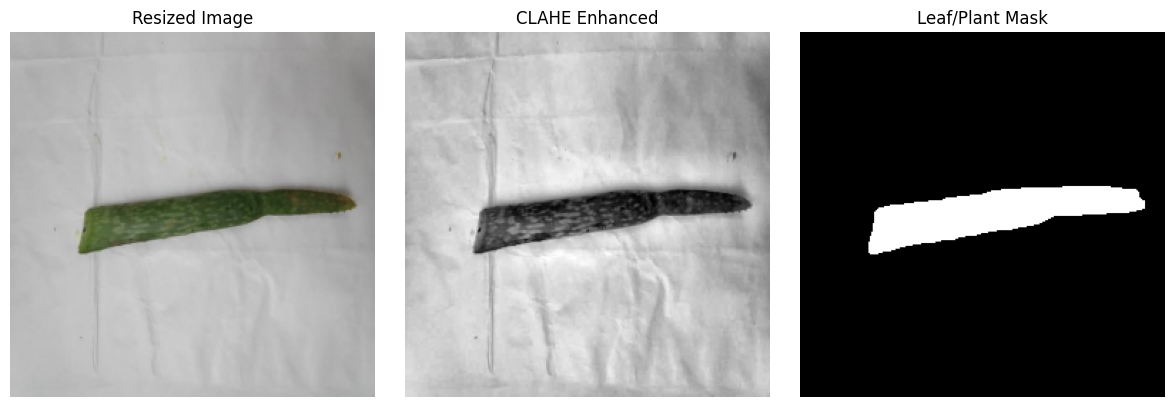

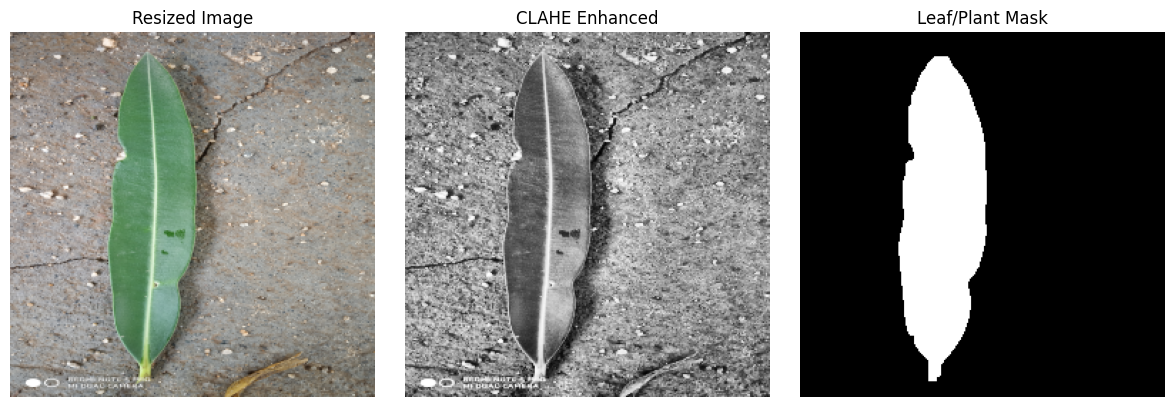

In [6]:
# ============================================================
# CELL 3A — PREPROCESSING VISUALS
# ============================================================

img_path = image_paths[10]

bgr, gray_eq, mask = load_and_segment(img_path)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
plt.title("Resized Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray_eq, cmap="gray")
plt.title("CLAHE Enhanced")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mask, cmap="gray")
plt.title("Leaf/Plant Mask")
plt.axis("off")

plt.tight_layout()
plt.show()






img_path = image_paths[2517]

bgr, gray_eq, mask = load_and_segment(img_path)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
plt.title("Resized Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray_eq, cmap="gray")
plt.title("CLAHE Enhanced")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mask, cmap="gray")
plt.title("Leaf/Plant Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# ============================================================
# CELL 4 — SHAPE FEATURES (Contour geometry + Hu moments)
# ============================================================
def extract_shape_features(mask):
    """
    Contour-geometry descriptors + the 7 Hu invariant moments.
    Hu moments are log-scaled because their raw values span enormous ranges
    (some are ~1e-10, others ~1) which would otherwise dominate distance-based
    classifiers (SVM/KNN) purely due to scale, not information content.
    Output length: 7 (geometry) + 7 (Hu) = 14
    """
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return np.zeros(14)

    cnt = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(cnt)
    perimeter = cv2.arcLength(cnt, True)
    x, y, w, h = cv2.boundingRect(cnt)
    aspect_ratio = w / h if h != 0 else 0
    hull = cv2.convexHull(cnt)
    hull_area = cv2.contourArea(hull)
    solidity = area / hull_area if hull_area != 0 else 0          # how "filled-in" vs. concave
    circularity = (4 * np.pi * area) / (perimeter ** 2) if perimeter != 0 else 0
    extent = area / (w * h) if (w * h) != 0 else 0                # area vs. bounding box area
    equiv_diameter = np.sqrt(4 * area / np.pi) if area > 0 else 0

    moments = cv2.moments(cnt)
    hu = cv2.HuMoments(moments).flatten()
    hu_log = -np.sign(hu) * np.log10(np.abs(hu) + 1e-30)          # log-scale, sign-preserving

    return np.concatenate([
        [area, perimeter, aspect_ratio, solidity, circularity, extent, equiv_diameter],
        hu_log
    ])


SHAPE_COLS = ["area", "perimeter", "aspect_ratio", "solidity", "circularity",
              "extent", "equiv_diameter"] + [f"hu_{i}" for i in range(7)]

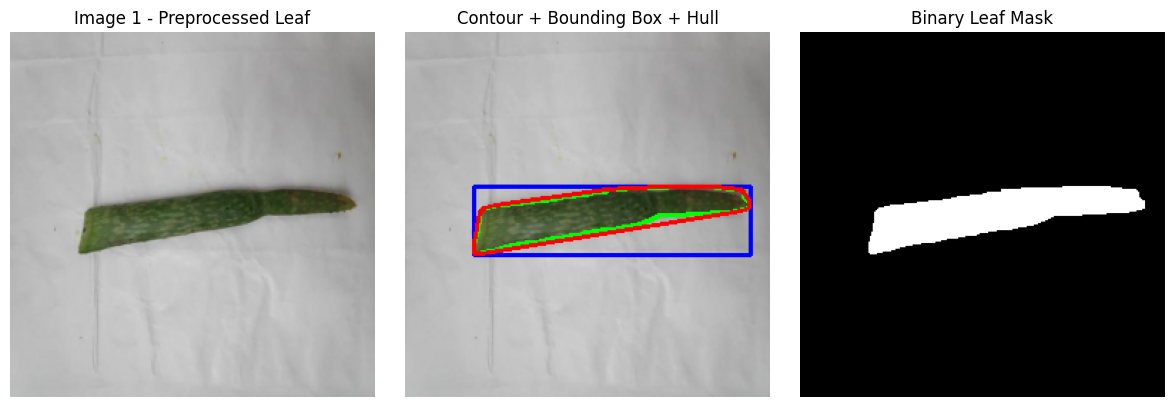


Image 1 — Extracted Shape Features:
area              : 4620.500000
perimeter         : 444.267026
aspect_ratio      : 4.041667
solidity          : 0.884560
circularity       : 0.294178
extent            : 0.496188
equiv_diameter    : 76.700739
hu_0              : 0.210048
hu_1              : 0.455627
hu_2              : 1.918553
hu_3              : 2.053516
hu_4              : 4.040078
hu_5              : 2.297334
hu_6              : -5.346717
--------------------------------------------------


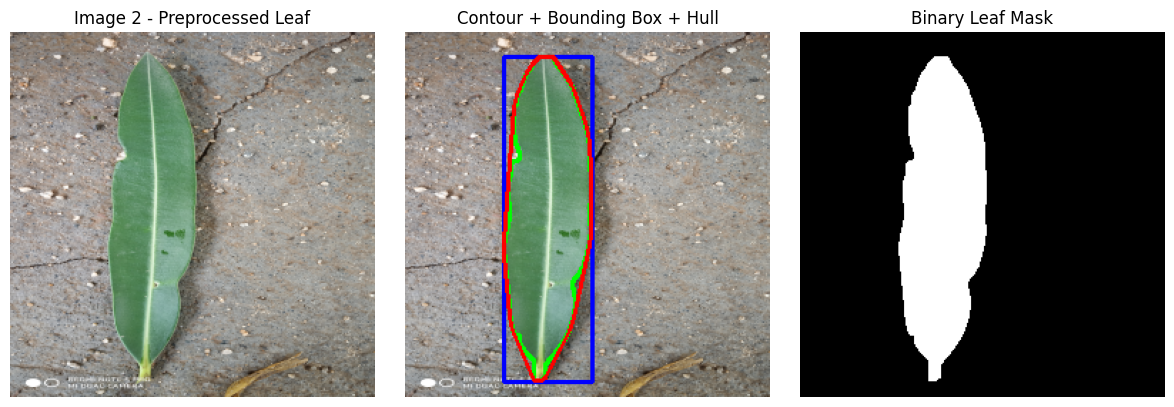


Image 2 — Extracted Shape Features:
area              : 9927.500000
perimeter         : 522.291411
aspect_ratio      : 0.271930
solidity          : 0.947868
circularity       : 0.457324
extent            : 0.702285
equiv_diameter    : 112.428135
hu_0              : 0.487597
hu_1              : 1.097781
hu_2              : 3.672080
hu_3              : 4.452186
hu_4              : 8.857614
hu_5              : 6.170349
hu_6              : -8.564349
--------------------------------------------------


In [8]:
# ============================================================
# CELL 4A — VISUALIZE SHAPE FEATURES FOR 2 IMAGES
# ============================================================
import matplotlib.pyplot as plt

# Select two different images
img_paths = [image_paths[10], image_paths[2517]]

for i, img_path in enumerate(img_paths, start=1):

    bgr, gray_eq, mask = load_and_segment(img_path)

    # Extract the 14 shape features
    shape_features = extract_shape_features(mask)

    # Find the largest contour
    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    if not contours:
        print(f"No contour found for Image {i}")
        continue

    cnt = max(contours, key=cv2.contourArea)

    # Create visualization
    visual = bgr.copy()

    # Draw leaf contour
    cv2.drawContours(
        visual, [cnt], -1, (0, 255, 0), 2
    )

    # Draw bounding rectangle
    x, y, w, h = cv2.boundingRect(cnt)
    cv2.rectangle(
        visual,
        (x, y),
        (x + w, y + h),
        (255, 0, 0),
        2
    )

    # Draw convex hull
    hull = cv2.convexHull(cnt)
    cv2.drawContours(
        visual, [hull], -1, (0, 0, 255), 2
    )

    # Display the three stages
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    plt.title(f"Image {i} - Preprocessed Leaf")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(cv2.cvtColor(visual, cv2.COLOR_BGR2RGB))
    plt.title("Contour + Bounding Box + Hull")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(mask, cmap="gray")
    plt.title("Binary Leaf Mask")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # Print extracted features
    print(f"\nImage {i} — Extracted Shape Features:")
    for name, value in zip(SHAPE_COLS, shape_features):
        print(f"{name:18s}: {value:.6f}")

    print("-" * 50)

In [10]:
# ============================================================
# CELL 5 — COLOR FEATURES (HSV histogram + color moments)
# ============================================================
def extract_color_features(bgr, mask, hist_bins=16):
    """
    Two complementary descriptions of leaf color, computed only over leaf
    pixels (mask), never the background:
      - HSV histogram: distribution shape of hue/saturation/value
      - Color moments: mean, std, skewness per channel (a compact 3-number
        summary of each channel's distribution)
    Output length: 3*hist_bins (histogram) + 3*3 (moments) = 48 + 9 = 57 (bins=16)
    """
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    mask_bool = mask > 0
    if mask_bool.sum() == 0:
        return np.zeros(3 * hist_bins + 9)

    hist_feats = []
    moment_feats = []
    ranges = [(0, 180), (0, 256), (0, 256)]  # H:0-180, S/V:0-255 in OpenCV
    for ch in range(3):
        channel_vals = hsv[:, :, ch][mask_bool].astype(np.float32)
        hist, _ = np.histogram(channel_vals, bins=hist_bins, range=ranges[ch], density=True)
        hist_feats.extend(hist)

        mean = channel_vals.mean()
        std = channel_vals.std()
        sk = skew(channel_vals) if channel_vals.std() > 1e-6 else 0.0
        moment_feats.extend([mean, std, sk])

    return np.array(hist_feats + moment_feats)


COLOR_HIST_BINS = 16
COLOR_COLS = ([f"h_hist_{i}" for i in range(COLOR_HIST_BINS)] +
              [f"s_hist_{i}" for i in range(COLOR_HIST_BINS)] +
              [f"v_hist_{i}" for i in range(COLOR_HIST_BINS)] +
              ["h_mean", "h_std", "h_skew", "s_mean", "s_std", "s_skew",
               "v_mean", "v_std", "v_skew"])

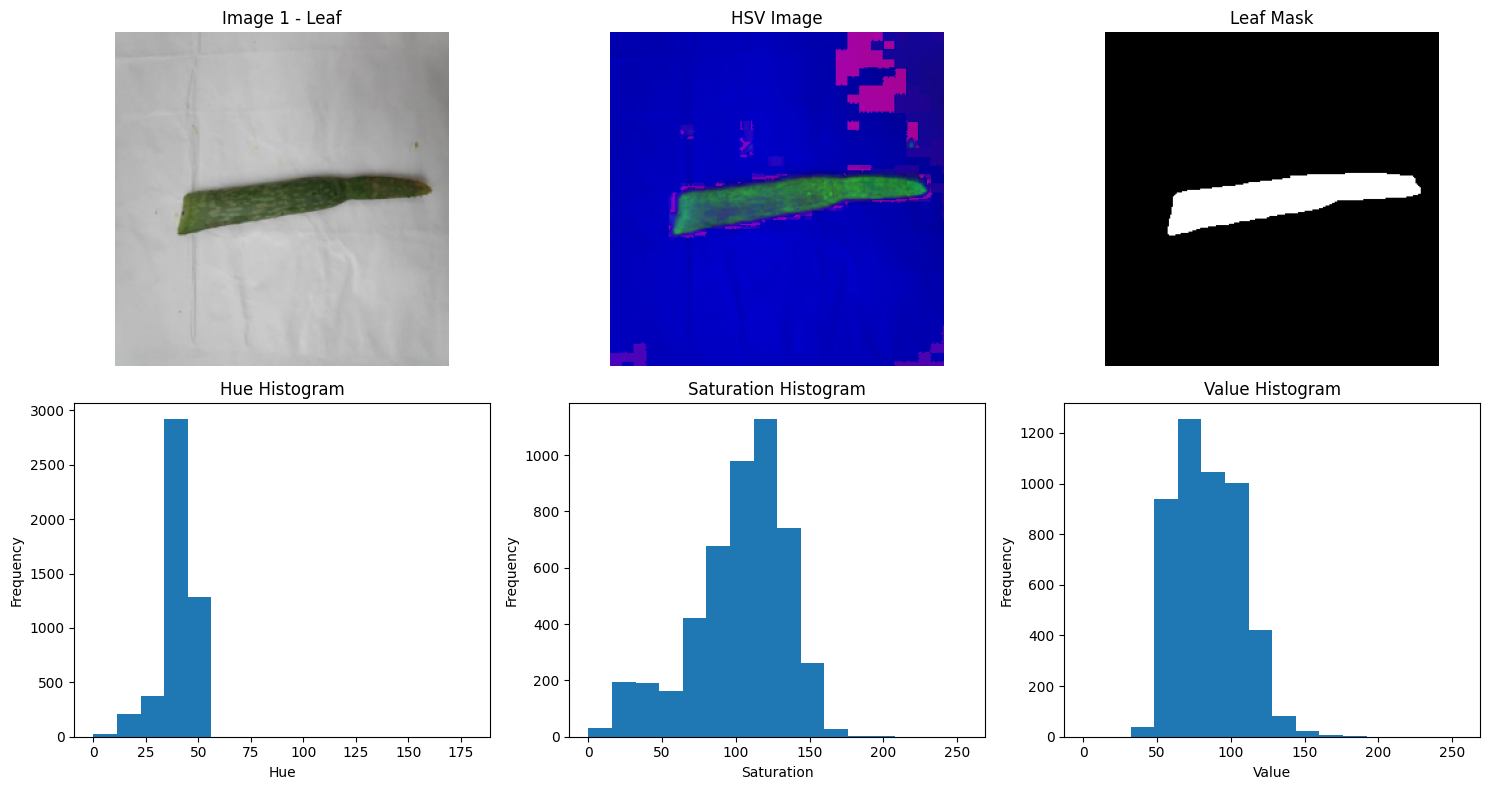


Image 1 — Extracted Color Features:
Total features: 57
h_hist_0          : 0.000388
h_hist_1          : 0.003913
h_hist_2          : 0.006921
h_hist_3          : 0.053894
h_hist_4          : 0.023754
h_hist_5          : 0.000000
h_hist_6          : 0.000000
h_hist_7          : 0.000000
h_hist_8          : 0.000000
h_hist_9          : 0.000000
h_hist_10         : 0.000000
h_hist_11         : 0.000000
h_hist_12         : 0.000000
h_hist_13         : 0.000000
h_hist_14         : 0.000000
h_hist_15         : 0.000018
s_hist_0          : 0.000402
s_hist_1          : 0.002518
s_hist_2          : 0.002453
s_hist_3          : 0.002115
s_hist_4          : 0.005477
s_hist_5          : 0.008773
s_hist_6          : 0.012692
s_hist_7          : 0.014639
s_hist_8          : 0.009616
s_hist_9          : 0.003400
s_hist_10         : 0.000376
s_hist_11         : 0.000026
s_hist_12         : 0.000013
s_hist_13         : 0.000000
s_hist_14         : 0.000000
s_hist_15         : 0.000000
v_hist_0        

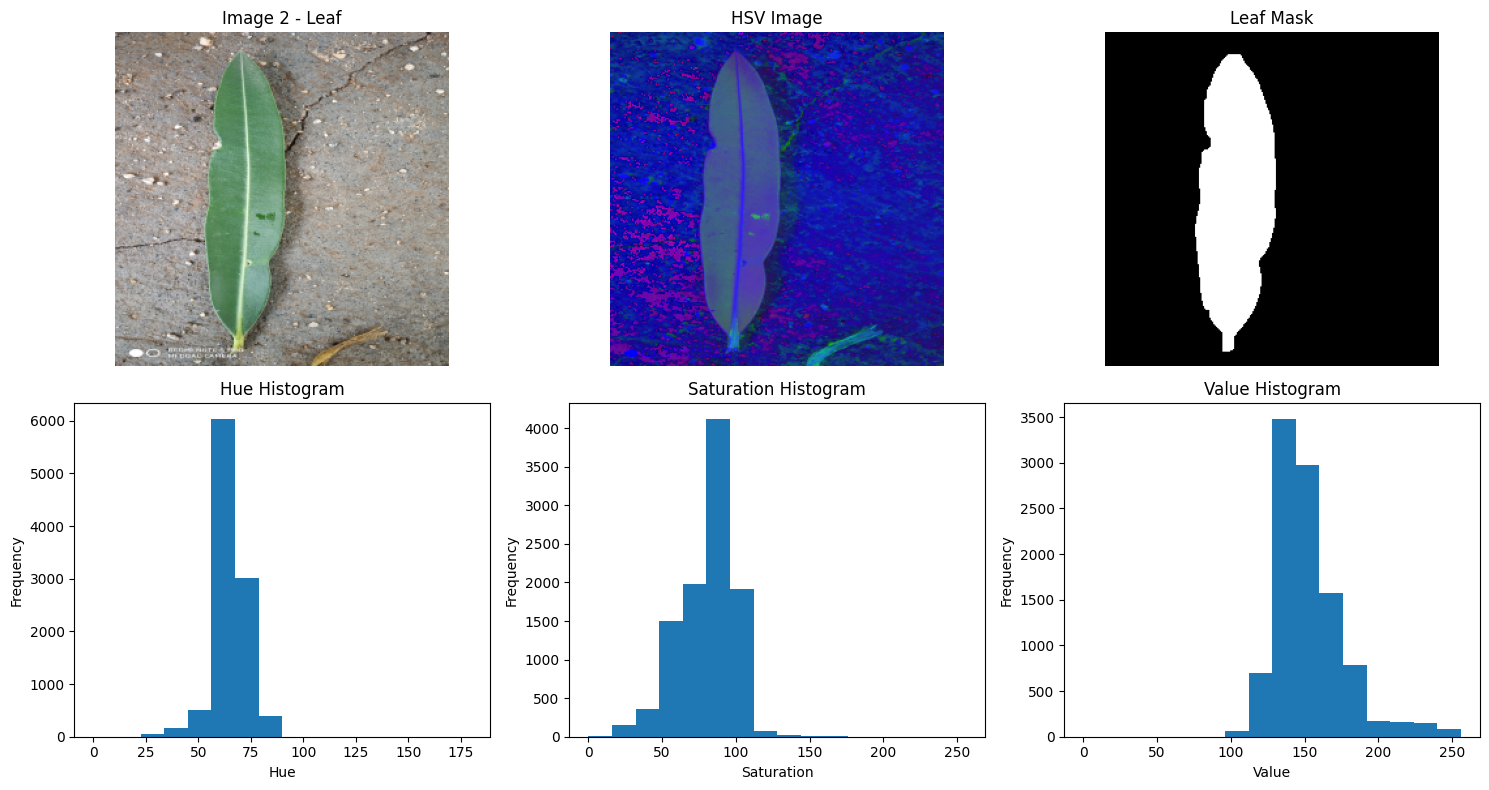


Image 2 — Extracted Color Features:
Total features: 57
h_hist_0          : 0.000000
h_hist_1          : 0.000026
h_hist_2          : 0.000473
h_hist_3          : 0.001419
h_hist_4          : 0.004405
h_hist_5          : 0.052808
h_hist_6          : 0.026386
h_hist_7          : 0.003372
h_hist_8          : 0.000000
h_hist_9          : 0.000000
h_hist_10         : 0.000000
h_hist_11         : 0.000000
h_hist_12         : 0.000000
h_hist_13         : 0.000000
h_hist_14         : 0.000000
h_hist_15         : 0.000000
s_hist_0          : 0.000018
s_hist_1          : 0.000924
s_hist_2          : 0.002180
s_hist_3          : 0.009255
s_hist_4          : 0.012217
s_hist_5          : 0.025357
s_hist_6          : 0.011823
s_hist_7          : 0.000468
s_hist_8          : 0.000129
s_hist_9          : 0.000055
s_hist_10         : 0.000062
s_hist_11         : 0.000012
s_hist_12         : 0.000000
s_hist_13         : 0.000000
s_hist_14         : 0.000000
s_hist_15         : 0.000000
v_hist_0        

In [11]:
# ============================================================
# CELL 5A — VISUALIZE COLOR FEATURES FOR 2 IMAGES
# ============================================================
import matplotlib.pyplot as plt

# Select two different images
img_paths = [image_paths[10], image_paths[2517]]

for i, img_path in enumerate(img_paths, start=1):

    # Preprocess image
    bgr, gray_eq, mask = load_and_segment(img_path)

    # Extract color features
    color_features = extract_color_features(
        bgr,
        mask,
        hist_bins=COLOR_HIST_BINS
    )

    # Convert to HSV
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)

    # Only leaf pixels
    mask_bool = mask > 0

    # --------------------------------------------------------
    # Create figure
    # --------------------------------------------------------
    plt.figure(figsize=(15, 8))

    # Original leaf
    plt.subplot(2, 3, 1)
    plt.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    plt.title(f"Image {i} - Leaf")
    plt.axis("off")

    # HSV representation
    plt.subplot(2, 3, 2)
    plt.imshow(hsv)
    plt.title("HSV Image")
    plt.axis("off")

    # Binary mask
    plt.subplot(2, 3, 3)
    plt.imshow(mask, cmap="gray")
    plt.title("Leaf Mask")
    plt.axis("off")

    # --------------------------------------------------------
    # HSV histograms
    # --------------------------------------------------------
    ranges = [
        (0, 180),
        (0, 256),
        (0, 256)
    ]

    channel_names = ["Hue", "Saturation", "Value"]

    for ch in range(3):

        channel_vals = hsv[:, :, ch][mask_bool].astype(np.float32)

        plt.subplot(2, 3, 4 + ch)

        plt.hist(
            channel_vals,
            bins=COLOR_HIST_BINS,
            range=ranges[ch]
        )

        plt.title(f"{channel_names[ch]} Histogram")
        plt.xlabel(channel_names[ch])
        plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # Print extracted color features
    # --------------------------------------------------------
    print(f"\nImage {i} — Extracted Color Features:")
    print(f"Total features: {len(color_features)}")

    for name, value in zip(COLOR_COLS, color_features):
        print(f"{name:18s}: {value:.6f}")

    print("-" * 60)

In [12]:
# ============================================================
# CELL 6 — TEXTURE FEATURES (GLCM + LBP + Gabor)
# ============================================================
def extract_texture_features(gray_eq, mask, lbp_bins=10):
    """
    Three complementary texture descriptors, each capturing a different
    notion of "surface pattern":
      - GLCM (Gray-Level Co-occurrence Matrix): how often pairs of gray
        levels occur next to each other -> contrast, homogeneity, energy, etc.
      - LBP (Local Binary Pattern): a per-pixel "texture code" histogram,
        robust to overall brightness changes.
      - Gabor filters: responses to a few orientation/frequency-tuned filters,
        good at picking up directional patterns (e.g. brushed/striated surfaces).
    Output length: 6 (GLCM) + lbp_bins (10) + 8*2 (Gabor mean/var) = 6+10+16 = 32
    """
    mask_bool = mask > 0
    if mask_bool.sum() == 0:
        return np.zeros(6 + lbp_bins + 16)

    # Restrict to a tight bounding box around the leaf so background pixels
    # (which would all be one flat gray level) don't distort GLCM/Gabor stats.
    ys, xs = np.where(mask_bool)
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    roi = gray_eq[y0:y1, x0:x1]

    # --- GLCM ---
    glcm = graycomatrix(roi, distances=[1], angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
                         levels=256, symmetric=True, normed=True)
    glcm_feats = [
        graycoprops(glcm, "contrast").mean(),
        graycoprops(glcm, "dissimilarity").mean(),
        graycoprops(glcm, "homogeneity").mean(),
        graycoprops(glcm, "energy").mean(),
        graycoprops(glcm, "correlation").mean(),
        graycoprops(glcm, "ASM").mean(),
    ]

    # --- LBP ---
    lbp = local_binary_pattern(gray_eq, P=8, R=1, method="uniform")
    lbp_vals = lbp[mask_bool]
    lbp_hist, _ = np.histogram(lbp_vals, bins=lbp_bins, range=(0, 10), density=True)

    # --- Gabor filter bank: 4 orientations x 2 frequencies = 8 filters ---
    gabor_feats = []
    for theta in [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]:
        for freq in [0.1, 0.3]:
            filt_real, _ = gabor(gray_eq, frequency=freq, theta=theta)
            vals = filt_real[mask_bool]
            gabor_feats.extend([vals.mean(), vals.var()])

    return np.concatenate([glcm_feats, lbp_hist, gabor_feats])


LBP_BINS = 10
TEXTURE_COLS = (["glcm_contrast", "glcm_dissimilarity", "glcm_homogeneity",
                  "glcm_energy", "glcm_correlation", "glcm_ASM"] +
                 [f"lbp_bin_{i}" for i in range(LBP_BINS)] +
                 [f"gabor_{i}" for i in range(16)])

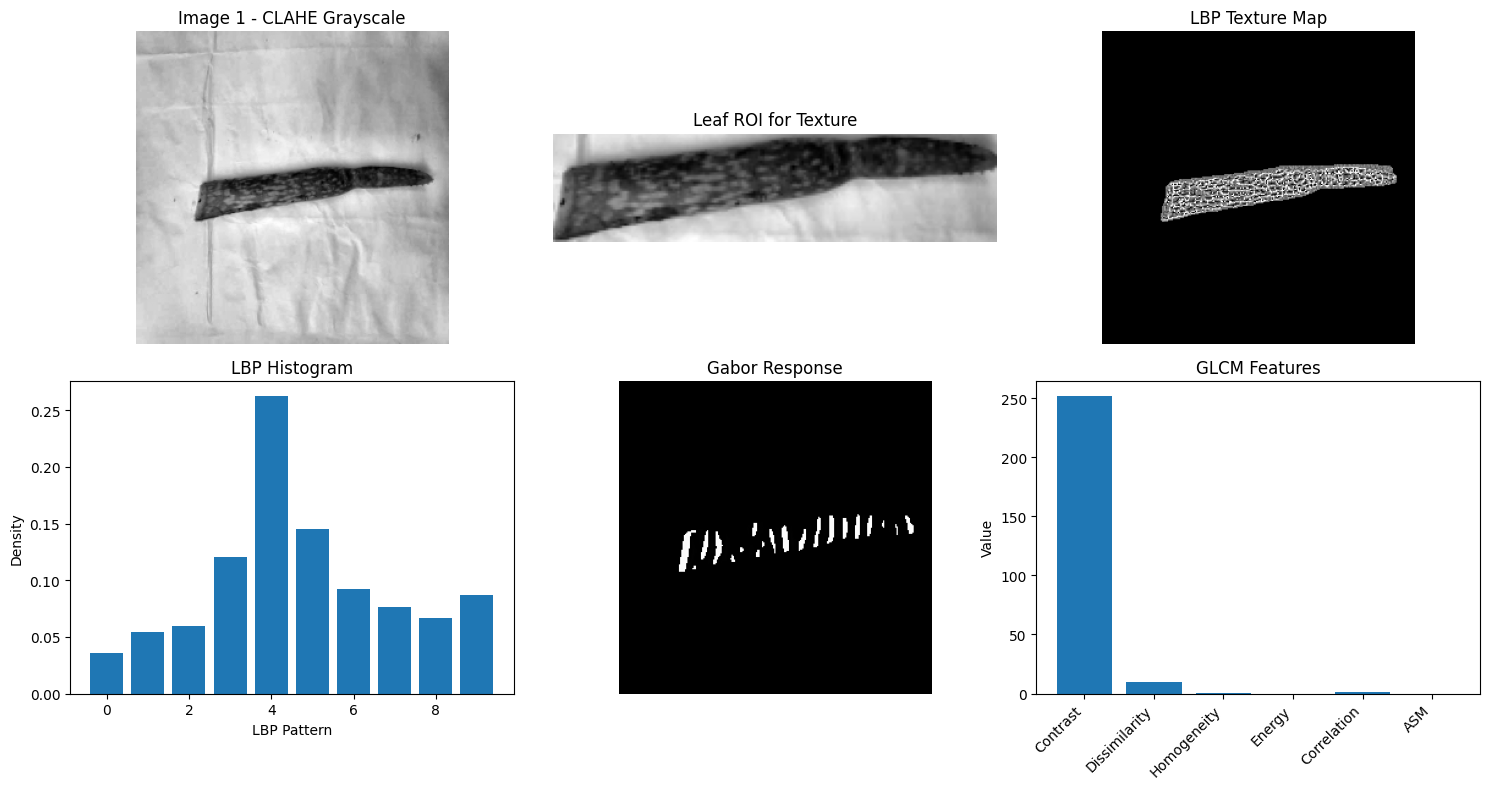


Image 1 — Extracted Texture Features:
Total features: 32
glcm_contrast         : 251.949709
glcm_dissimilarity    : 9.823008
glcm_homogeneity      : 0.158957
glcm_energy           : 0.018318
glcm_correlation      : 0.966697
glcm_ASM              : 0.000342
lbp_bin_0             : 0.035608
lbp_bin_1             : 0.054048
lbp_bin_2             : 0.059559
lbp_bin_3             : 0.120178
lbp_bin_4             : 0.262611
lbp_bin_5             : 0.145613
lbp_bin_6             : 0.091988
lbp_bin_7             : 0.076304
lbp_bin_8             : 0.066766
lbp_bin_9             : 0.087325
gabor_0               : 58.150487
gabor_1               : 11313.265187
gabor_2               : 25.051081
gabor_3               : 5706.883995
gabor_4               : 80.350996
gabor_5               : 13890.263406
gabor_6               : 51.801187
gabor_7               : 10439.975310
gabor_8               : 124.108097
gabor_9               : 15553.614428
gabor_10              : 80.738025
gabor_11              :

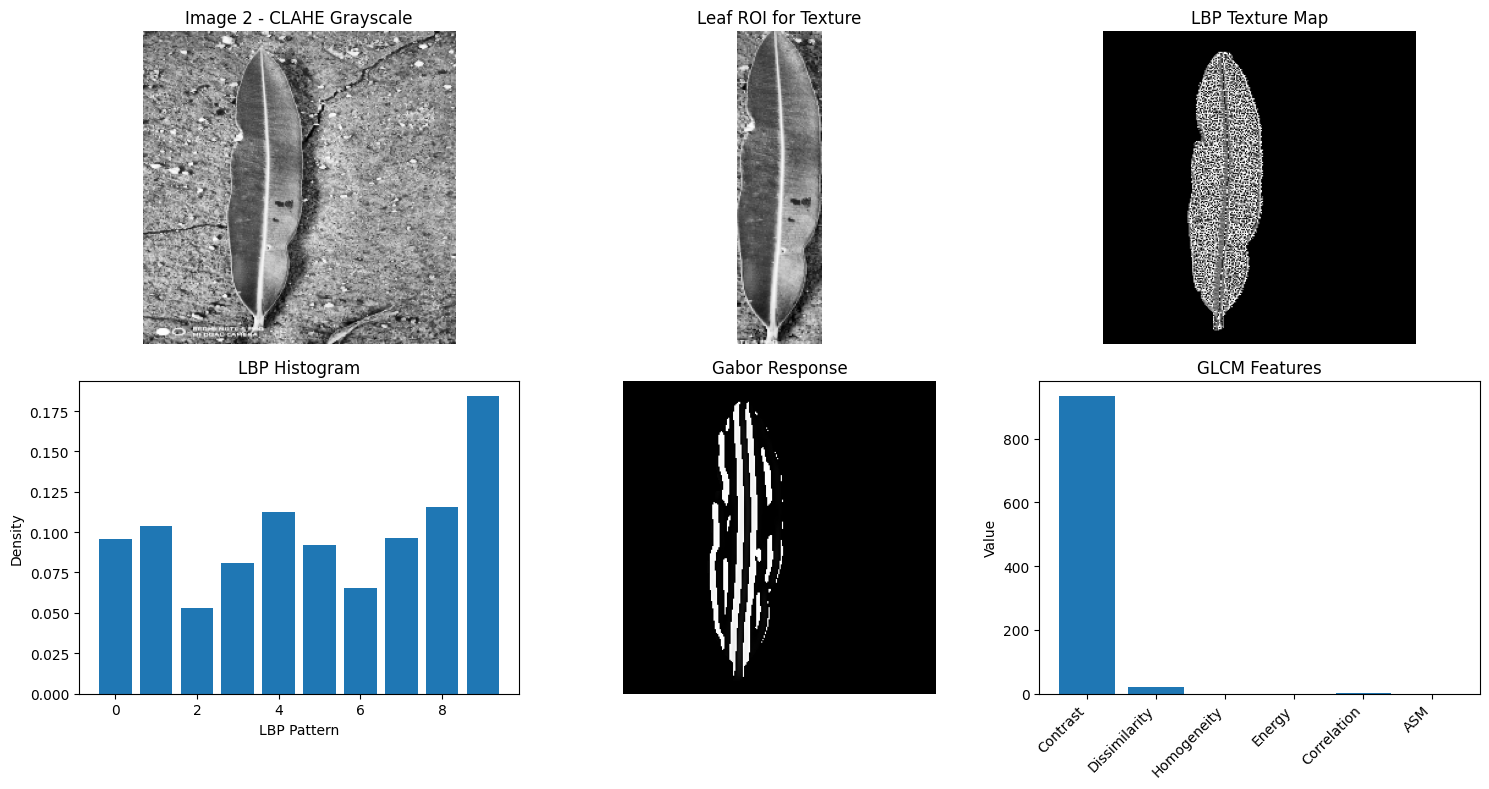


Image 2 — Extracted Texture Features:
Total features: 32
glcm_contrast         : 933.598951
glcm_dissimilarity    : 19.945762
glcm_homogeneity      : 0.075503
glcm_energy           : 0.012171
glcm_correlation      : 0.787084
glcm_ASM              : 0.000148
lbp_bin_0             : 0.095781
lbp_bin_1             : 0.103550
lbp_bin_2             : 0.053299
lbp_bin_3             : 0.081129
lbp_bin_4             : 0.112499
lbp_bin_5             : 0.092143
lbp_bin_6             : 0.065198
lbp_bin_7             : 0.096175
lbp_bin_8             : 0.115842
lbp_bin_9             : 0.184384
gabor_0               : 93.461501
gabor_1               : 14065.147721
gabor_2               : 55.194218
gabor_3               : 10664.090611
gabor_4               : 41.308585
gabor_5               : 8692.899170
gabor_6               : 31.689448
gabor_7               : 6982.057162
gabor_8               : 47.497984
gabor_9               : 9708.052730
gabor_10              : 44.699184
gabor_11              : 9

In [13]:
# ============================================================
# CELL 6A — VISUALIZE TEXTURE FEATURES FOR 2 IMAGES
# ============================================================
import matplotlib.pyplot as plt

# Select two different images
img_paths = [image_paths[10], image_paths[2517]]

for i, img_path in enumerate(img_paths, start=1):

    # --------------------------------------------------------
    # Preprocess image
    # --------------------------------------------------------
    bgr, gray_eq, mask = load_and_segment(img_path)

    # --------------------------------------------------------
    # Extract texture features
    # --------------------------------------------------------
    texture_features = extract_texture_features(
        gray_eq,
        mask,
        lbp_bins=LBP_BINS
    )

    # --------------------------------------------------------
    # Create leaf ROI
    # --------------------------------------------------------
    mask_bool = mask > 0

    ys, xs = np.where(mask_bool)

    if len(ys) == 0:
        print(f"No valid mask found for Image {i}")
        continue

    y0, y1 = ys.min(), ys.max() + 1
    x0, x1 = xs.min(), xs.max() + 1

    roi = gray_eq[y0:y1, x0:x1]

    # --------------------------------------------------------
    # LBP
    # --------------------------------------------------------
    lbp = local_binary_pattern(
        gray_eq,
        P=8,
        R=1,
        method="uniform"
    )

    # Keep only leaf pixels
    lbp_leaf = np.zeros_like(lbp)
    lbp_leaf[mask_bool] = lbp[mask_bool]

    lbp_vals = lbp[mask_bool]

    # --------------------------------------------------------
    # Gabor response for visualization
    # --------------------------------------------------------
    # One representative Gabor filter
    gabor_real, _ = gabor(
        gray_eq,
        frequency=0.1,
        theta=0
    )

    gabor_leaf = np.zeros_like(gabor_real)
    gabor_leaf[mask_bool] = gabor_real[mask_bool]

    # --------------------------------------------------------
    # GLCM
    # --------------------------------------------------------
    glcm = graycomatrix(
        roi,
        distances=[1],
        angles=[
            0,
            np.pi / 4,
            np.pi / 2,
            3 * np.pi / 4
        ],
        levels=256,
        symmetric=True,
        normed=True
    )

    glcm_features = [
        graycoprops(glcm, "contrast").mean(),
        graycoprops(glcm, "dissimilarity").mean(),
        graycoprops(glcm, "homogeneity").mean(),
        graycoprops(glcm, "energy").mean(),
        graycoprops(glcm, "correlation").mean(),
        graycoprops(glcm, "ASM").mean()
    ]

    # --------------------------------------------------------
    # LBP histogram
    # --------------------------------------------------------
    lbp_hist, _ = np.histogram(
        lbp_vals,
        bins=LBP_BINS,
        range=(0, 10),
        density=True
    )

    # --------------------------------------------------------
    # Display texture visualizations
    # --------------------------------------------------------
    plt.figure(figsize=(15, 8))

    # 1. CLAHE grayscale
    plt.subplot(2, 3, 1)
    plt.imshow(gray_eq, cmap="gray")
    plt.title(f"Image {i} - CLAHE Grayscale")
    plt.axis("off")

    # 2. Leaf ROI
    plt.subplot(2, 3, 2)
    plt.imshow(roi, cmap="gray")
    plt.title("Leaf ROI for Texture")
    plt.axis("off")

    # 3. LBP image
    plt.subplot(2, 3, 3)
    plt.imshow(lbp_leaf, cmap="gray")
    plt.title("LBP Texture Map")
    plt.axis("off")

    # 4. LBP histogram
    plt.subplot(2, 3, 4)
    plt.bar(range(LBP_BINS), lbp_hist)
    plt.title("LBP Histogram")
    plt.xlabel("LBP Pattern")
    plt.ylabel("Density")

    # 5. Gabor response
    plt.subplot(2, 3, 5)
    plt.imshow(gabor_leaf, cmap="gray")
    plt.title("Gabor Response")
    plt.axis("off")

    # 6. GLCM feature values
    plt.subplot(2, 3, 6)
    glcm_names = [
        "Contrast",
        "Dissimilarity",
        "Homogeneity",
        "Energy",
        "Correlation",
        "ASM"
    ]

    plt.bar(range(6), glcm_features)
    plt.xticks(
        range(6),
        glcm_names,
        rotation=45,
        ha="right"
    )
    plt.title("GLCM Features")
    plt.ylabel("Value")

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # Print all extracted texture features
    # --------------------------------------------------------
    print(f"\nImage {i} — Extracted Texture Features:")
    print(f"Total features: {len(texture_features)}")

    for name, value in zip(TEXTURE_COLS, texture_features):
        print(f"{name:22s}: {value:.6f}")

    print("-" * 70)

In [14]:
# ============================================================
# CELL 7 — VEIN/EDGE-STRUCTURE FEATURES
# ============================================================
def extract_vein_edge_features(gray_eq, mask, orientation_bins=8):
    """
    Extracts vein/edge structure from the leaf.

    Features:
      - Canny edge density
      - vein/skeleton density
      - branch count
      - endpoint count
      - mean vein thickness
      - std vein thickness
      - 8-bin vein orientation histogram

    Output length = 6 + orientation_bins = 14
    """

    mask_bool = mask > 0
    leaf_area = mask_bool.sum()

    if leaf_area == 0:
        return np.zeros(6 + orientation_bins)

    # --------------------------------------------------------
    # Restrict analysis slightly inside the leaf boundary.
    # This prevents the outer leaf contour from dominating
    # the vein detection.
    # --------------------------------------------------------
    kernel = np.ones((5, 5), np.uint8)

    inner_mask = cv2.erode(
        mask,
        kernel,
        iterations=1
    )

    inner_bool = inner_mask > 0

    if inner_bool.sum() == 0:
        inner_bool = mask_bool

    # --------------------------------------------------------
    # 1. Canny edge density
    # --------------------------------------------------------
    edges = cv2.Canny(
        gray_eq,
        50,
        150
    )

    edges_in_leaf = edges.copy()
    edges_in_leaf[~inner_bool] = 0

    edge_density = (
        np.count_nonzero(edges_in_leaf)
        / inner_bool.sum()
    )

    # --------------------------------------------------------
    # 2. Detect vein-like structures
    # --------------------------------------------------------
    # Black-hat detects dark line-like structures on a
    # relatively bright background.
    blackhat = cv2.morphologyEx(
        gray_eq,
        cv2.MORPH_BLACKHAT,
        np.ones((9, 9), np.uint8)
    )

    # White-hat detects bright line-like structures.
    whitehat = cv2.morphologyEx(
        gray_eq,
        cv2.MORPH_TOPHAT,
        np.ones((9, 9), np.uint8)
    )

    # Combine both so the method can capture veins that are
    # either darker or brighter than their surroundings.
    vein_response = cv2.max(
        blackhat,
        whitehat
    )

    vein_response[~inner_bool] = 0

    # --------------------------------------------------------
    # Threshold vein response
    # --------------------------------------------------------
    vein_pixels = vein_response[inner_bool]

    if len(vein_pixels) == 0:
        return np.zeros(6 + orientation_bins)

    threshold = max(
        5,
        np.percentile(vein_pixels, 70)
    )

    vein_binary = np.zeros_like(
        vein_response,
        dtype=np.uint8
    )

    vein_binary[
        (vein_response >= threshold) & inner_bool
    ] = 1

    # Remove tiny noise
    small_kernel = np.ones(
        (3, 3),
        np.uint8
    )

    vein_binary = cv2.morphologyEx(
        vein_binary,
        cv2.MORPH_OPEN,
        small_kernel
    )

    # --------------------------------------------------------
    # 3. Skeletonize the detected vein structures
    # --------------------------------------------------------
    skeleton = skeletonize(
        vein_binary > 0
    ).astype(np.uint8)

    skeleton_pixels = skeleton.sum()

    vein_density = (
        skeleton_pixels / inner_bool.sum()
    )

    # --------------------------------------------------------
    # 4. Branch and endpoint counts
    # --------------------------------------------------------
    branch_count = 0
    endpoint_count = 0

    if skeleton_pixels > 0:

        kernel_neighbors = np.ones(
            (3, 3),
            np.uint8
        )

        neighbor_count = cv2.filter2D(
            skeleton,
            -1,
            kernel_neighbors
        )

        neighbor_values = (
            neighbor_count[skeleton.astype(bool)] - 1
        )

        endpoint_count = int(
            (neighbor_values == 1).sum()
        )

        branch_count = int(
            (neighbor_values >= 3).sum()
        )

    # --------------------------------------------------------
    # 5. Vein thickness
    # --------------------------------------------------------
    distance_map = distance_transform_edt(
        vein_binary
    )

    if skeleton_pixels > 0:

        skeleton_values = distance_map[
            skeleton.astype(bool)
        ]

        mean_thickness = skeleton_values.mean()
        std_thickness = skeleton_values.std()

    else:

        mean_thickness = 0.0
        std_thickness = 0.0

    # --------------------------------------------------------
    # 6. Vein orientation
    # --------------------------------------------------------
    sobelx = cv2.Sobel(
        gray_eq,
        cv2.CV_64F,
        1,
        0,
        ksize=3
    )

    sobely = cv2.Sobel(
        gray_eq,
        cv2.CV_64F,
        0,
        1,
        ksize=3
    )

    angles = np.arctan2(
        sobely,
        sobelx
    )

    # Calculate orientation only around detected vein pixels
    vein_angles = angles[
        vein_binary.astype(bool)
    ]

    if len(vein_angles) > 0:

        orient_hist, _ = np.histogram(
            vein_angles,
            bins=orientation_bins,
            range=(-np.pi, np.pi),
            density=True
        )

    else:

        orient_hist = np.zeros(
            orientation_bins
        )

    # --------------------------------------------------------
    # Final 14-dimensional feature vector
    # --------------------------------------------------------
    return np.concatenate([
        [
            edge_density,
            vein_density,
            branch_count,
            endpoint_count,
            mean_thickness,
            std_thickness
        ],
        orient_hist
    ])


VEIN_COLS = (
    [
        "edge_density",
        "vein_density",
        "branch_count",
        "endpoint_count",
        "mean_thickness",
        "std_thickness"
    ]
    +
    [
        f"edge_orient_bin_{i}"
        for i in range(8)
    ]
)

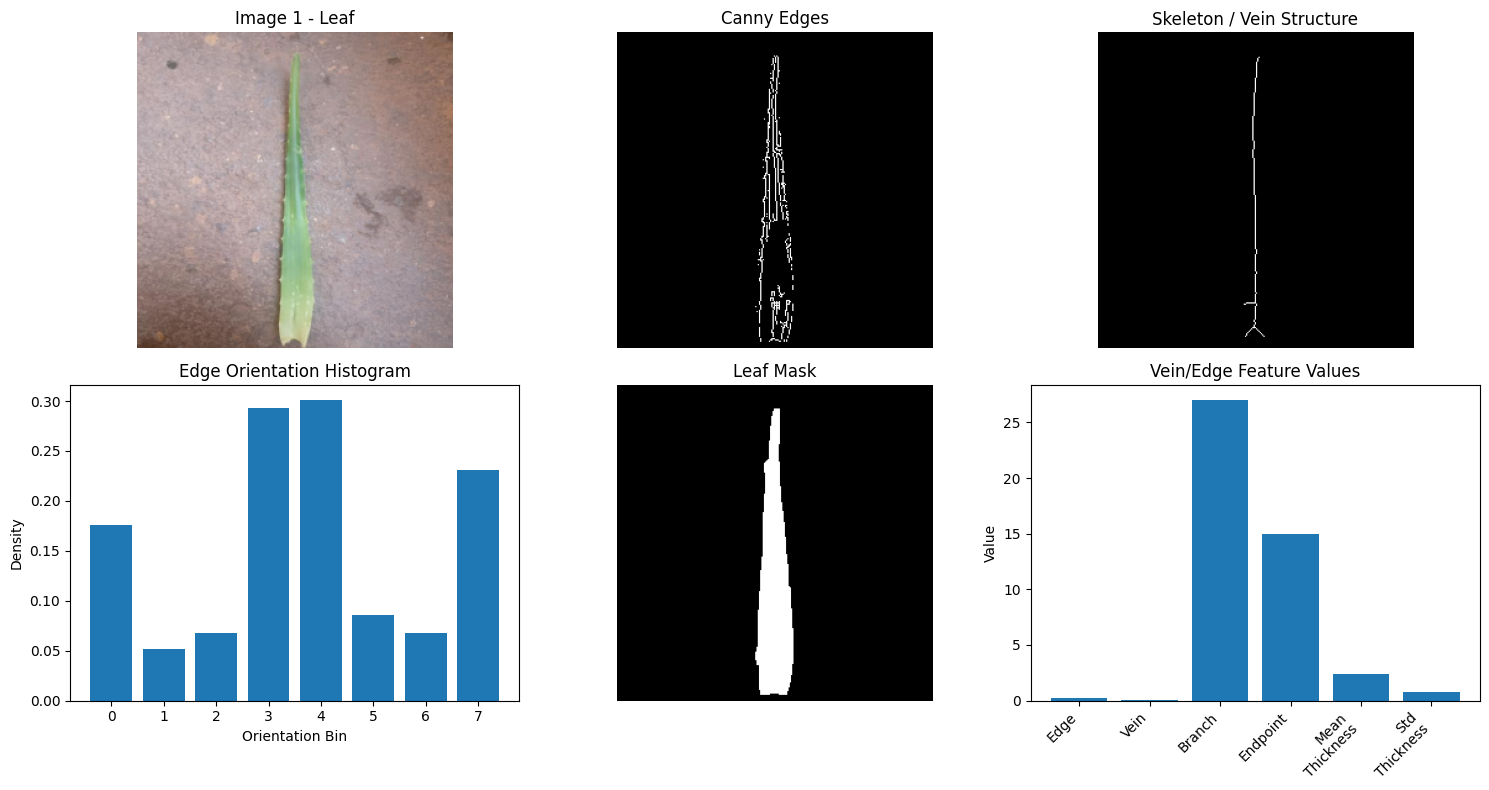


Image 1 — Extracted Vein/Edge Features:
Total features: 14
edge_density            : 0.188834
vein_density            : 0.051155
branch_count            : 27.000000
endpoint_count          : 15.000000
mean_thickness          : 2.421281
std_thickness           : 0.792985
edge_orient_bin_0       : 0.151228
edge_orient_bin_1       : 0.022765
edge_orient_bin_2       : 0.040653
edge_orient_bin_3       : 0.317090
edge_orient_bin_4       : 0.282942
edge_orient_bin_5       : 0.060166
edge_orient_bin_6       : 0.056914
edge_orient_bin_7       : 0.341482
----------------------------------------------------------------------


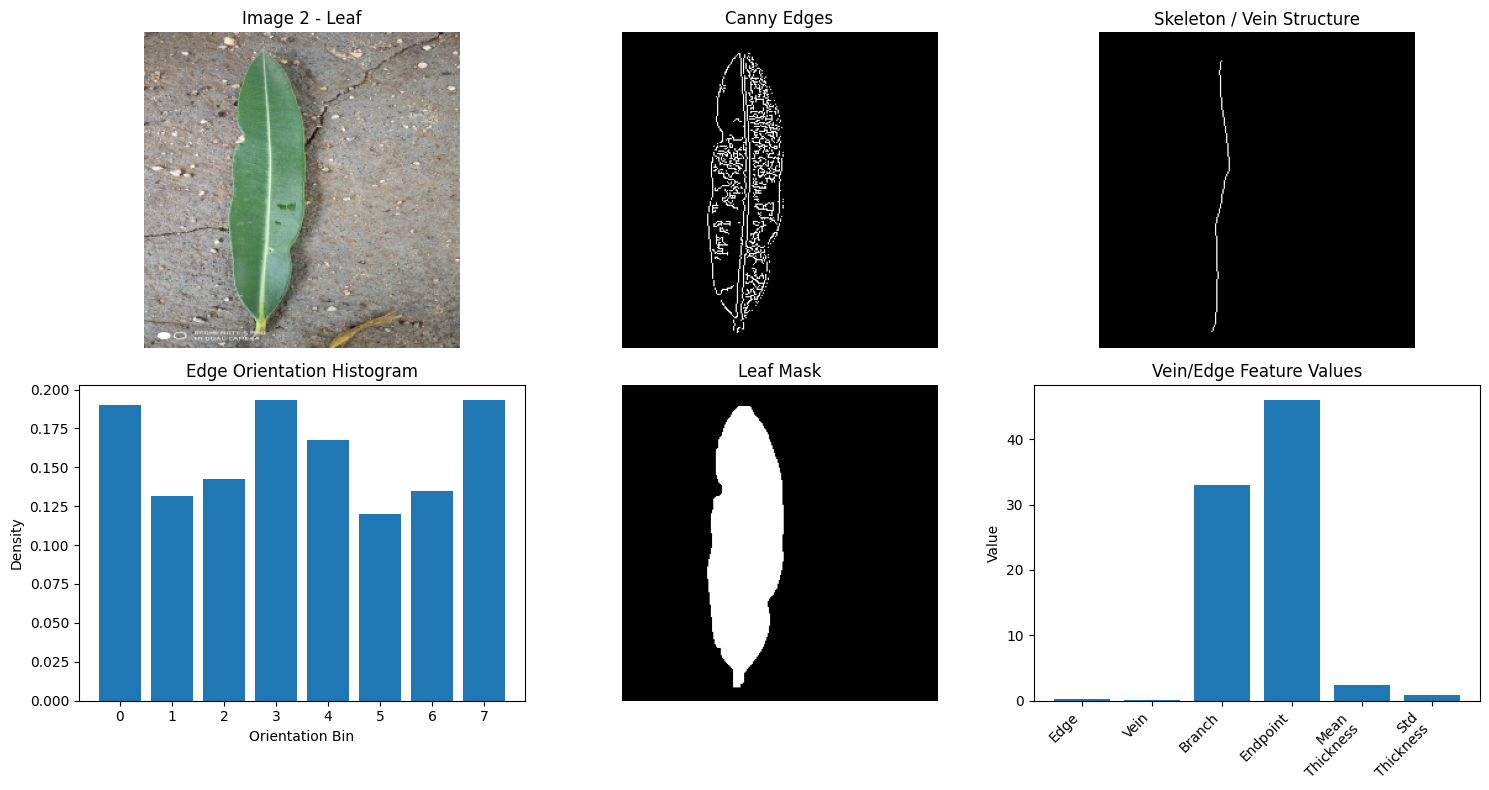


Image 2 — Extracted Vein/Edge Features:
Total features: 14
edge_density            : 0.232709
vein_density            : 0.035921
branch_count            : 33.000000
endpoint_count          : 46.000000
mean_thickness          : 2.322930
std_thickness           : 0.810425
edge_orient_bin_0       : 0.259349
edge_orient_bin_1       : 0.064837
edge_orient_bin_2       : 0.076994
edge_orient_bin_3       : 0.248813
edge_orient_bin_4       : 0.254486
edge_orient_bin_5       : 0.055112
edge_orient_bin_6       : 0.080236
edge_orient_bin_7       : 0.233414
----------------------------------------------------------------------


In [15]:
# ============================================================
# CELL 7A — VISUALIZE VEIN/EDGE FEATURES FOR 2 IMAGES
# ============================================================
import matplotlib.pyplot as plt

# Select two images
img_paths = [image_paths[12], image_paths[2517]]

for i, img_path in enumerate(img_paths, start=1):

    # --------------------------------------------------------
    # Preprocess image
    # --------------------------------------------------------
    bgr, gray_eq, mask = load_and_segment(img_path)

    # --------------------------------------------------------
    # Extract vein/edge features
    # --------------------------------------------------------
    vein_features = extract_vein_edge_features(
        gray_eq,
        mask,
        orientation_bins=8
    )

    mask_bool = mask > 0

    # --------------------------------------------------------
    # Canny edges
    # --------------------------------------------------------
    edges = cv2.Canny(gray_eq, 50, 150)

    edges_in_leaf = edges.copy()
    edges_in_leaf[~mask_bool] = 0

    # --------------------------------------------------------
    # Skeleton
    # --------------------------------------------------------
    binary = mask_bool.astype(np.uint8)
    skeleton = skeletonize(binary).astype(np.uint8)

    # --------------------------------------------------------
    # Sobel edge orientation
    # --------------------------------------------------------
    sobelx = cv2.Sobel(
        gray_eq,
        cv2.CV_64F,
        1,
        0,
        ksize=3
    )

    sobely = cv2.Sobel(
        gray_eq,
        cv2.CV_64F,
        0,
        1,
        ksize=3
    )

    angles = np.arctan2(sobely, sobelx)

    # Only leaf pixels
    leaf_angles = angles[mask_bool]

    orientation_hist, _ = np.histogram(
        leaf_angles,
        bins=8,
        range=(-np.pi, np.pi),
        density=True
    )

    # --------------------------------------------------------
    # Create visualization
    # --------------------------------------------------------
    plt.figure(figsize=(15, 8))

    # 1. Original leaf
    plt.subplot(2, 3, 1)
    plt.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    plt.title(f"Image {i} - Leaf")
    plt.axis("off")

    # 2. Canny edges
    plt.subplot(2, 3, 2)
    plt.imshow(edges_in_leaf, cmap="gray")
    plt.title("Canny Edges")
    plt.axis("off")

    # 3. Skeleton
    plt.subplot(2, 3, 3)
    plt.imshow(skeleton, cmap="gray")
    plt.title("Skeleton / Vein Structure")
    plt.axis("off")

    # 4. Edge orientation histogram
    plt.subplot(2, 3, 4)

    plt.bar(
        range(8),
        orientation_hist
    )

    plt.title("Edge Orientation Histogram")
    plt.xlabel("Orientation Bin")
    plt.ylabel("Density")
    plt.xticks(range(8))

    # 5. Leaf mask
    plt.subplot(2, 3, 5)
    plt.imshow(mask, cmap="gray")
    plt.title("Leaf Mask")
    plt.axis("off")

    # 6. Feature summary
    plt.subplot(2, 3, 6)

    feature_names = [
        "Edge",
        "Vein",
        "Branch",
        "Endpoint",
        "Mean\nThickness",
        "Std\nThickness"
    ]

    # First 6 features
    plt.bar(
        range(6),
        vein_features[:6]
    )

    plt.xticks(
        range(6),
        feature_names,
        rotation=45,
        ha="right"
    )

    plt.title("Vein/Edge Feature Values")
    plt.ylabel("Value")

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # Print extracted features
    # --------------------------------------------------------
    print(f"\nImage {i} — Extracted Vein/Edge Features:")
    print(f"Total features: {len(vein_features)}")

    for name, value in zip(VEIN_COLS, vein_features):
        print(f"{name:24s}: {value:.6f}")

    print("-" * 70)

In [17]:
# ============================================================
# CELL 7A — PHASE A: run ALL preprocessing + feature extraction (parallel)
# ============================================================

def process_one_image(args):
    idx, path = args
    bgr, gray_eq, mask = load_and_segment(path)
    if bgr is None or mask is None or mask.sum() == 0:
        return (idx, None, None, None, None)

    shape_f = extract_shape_features(mask)
    color_f = extract_color_features(bgr, mask)
    texture_f = extract_texture_features(gray_eq, mask)
    vein_f = extract_vein_edge_features(gray_eq, mask)
  

    return (idx, shape_f, color_f, texture_f, vein_f)


print(f"Running feature extraction (Phase A) across {cpu_count()} cores for {N} images...")
start = time.time()
with Pool(processes=cpu_count()) as pool:
    phase_a_results = pool.map(process_one_image, list(enumerate(image_paths)))
print(f"Phase A done in {time.time() - start:.1f}s")

# Sort back into original index order (Pool.map preserves order, but be explicit/safe)
phase_a_results.sort(key=lambda r: r[0])

# Pre-allocate feature matrices; failed images become all-zero rows (and are
# also tracked in `valid_mask` so you can inspect/drop them if needed).
X_shape = np.zeros((N, len(SHAPE_COLS)))
X_color = np.zeros((N, len(COLOR_COLS)))
X_texture = np.zeros((N, len(TEXTURE_COLS)))
X_vein = np.zeros((N, len(VEIN_COLS)))
valid_mask = np.zeros(N, dtype=bool)

for idx, shape_f, color_f, texture_f, vein_f in phase_a_results:
    if shape_f is None:
        continue
    X_shape[idx] = shape_f
    X_color[idx] = color_f
    X_texture[idx] = texture_f
    X_vein[idx] = vein_f
    valid_mask[idx] = True

print(f"Valid images: {valid_mask.sum()} / {N}  (failed reads/empty masks excluded)")

Running feature extraction (Phase A) across 4 cores for 6900 images...


Corrupt JPEG data: premature end of data segment
Corrupt JPEG data: premature end of data segment
Corrupt JPEG data: 441 extraneous bytes before marker 0xd9


Phase A done in 3837.6s
Valid images: 6843 / 6900  (failed reads/empty masks excluded)


In [19]:
# # ============================================================
# # CELL 7B — Save the full combined raw feature table (for reuse/inspection)
# # ============================================================
feature_groups_raw = {
    "shape": (X_shape, SHAPE_COLS),
    "color": (X_color, COLOR_COLS),
    "texture": (X_texture, TEXTURE_COLS),
    "vein": (X_vein, VEIN_COLS),
   
}

all_cols = []
all_arrays = []
for name, (arr, cols) in feature_groups_raw.items():
    all_cols.extend([f"{name}__{c}" for c in cols])
    all_arrays.append(arr)

full_df = pd.DataFrame(np.hstack(all_arrays), columns=all_cols)
full_df["label"] = raw_labels
full_df["is_valid"] = valid_mask
full_df.to_csv(os.path.join(OUTPUT_DIR, "all_features_raw.csv"), index=False)
print(f"Saved raw combined feature table -> {OUTPUT_DIR}/all_features_raw.csv  shape={full_df.shape}")

Saved raw combined feature table -> /kaggle/working/all_features_raw.csv  shape=(6900, 119)


In [25]:
# ============================================================
# CELL 8 — THREE-WAY STRATIFIED SPLIT (TRAIN / VALIDATION / TEST)
# ============================================================
from sklearn.model_selection import train_test_split as _tts

# 70% train / 15% validation / 15% test, stratified so every species is
# represented proportionally in all three sets even with 80 classes.
TRAIN_IDX, temp_idx, y_train_full, y_temp = _tts(
    np.arange(len(y_all)), y_all,
    test_size=0.30, random_state=RANDOM_STATE, stratify=y_all
)
VAL_IDX, TEST_IDX, y_val_full, y_test_full = _tts(
    temp_idx, y_temp,
    test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print(f"TRAIN:      {len(TRAIN_IDX):5d} images ({len(TRAIN_IDX)/len(y_all)*100:.1f}%)")
print(f"VALIDATION: {len(VAL_IDX):5d} images ({len(VAL_IDX)/len(y_all)*100:.1f}%)")
print(f"TEST:       {len(TEST_IDX):5d} images ({len(TEST_IDX)/len(y_all)*100:.1f}%)")

# Sanity check: confirm no index appears in more than one split.
assert len(set(TRAIN_IDX) & set(VAL_IDX)) == 0
assert len(set(TRAIN_IDX) & set(TEST_IDX)) == 0
assert len(set(VAL_IDX) & set(TEST_IDX)) == 0
print("\nNo overlap between splits — confirmed.")

y_tr = y_all[TRAIN_IDX]
y_va = y_all[VAL_IDX]
y_te = y_all[TEST_IDX]

TRAIN:       4830 images (70.0%)
VALIDATION:  1035 images (15.0%)
TEST:        1035 images (15.0%)

No overlap between splits — confirmed.


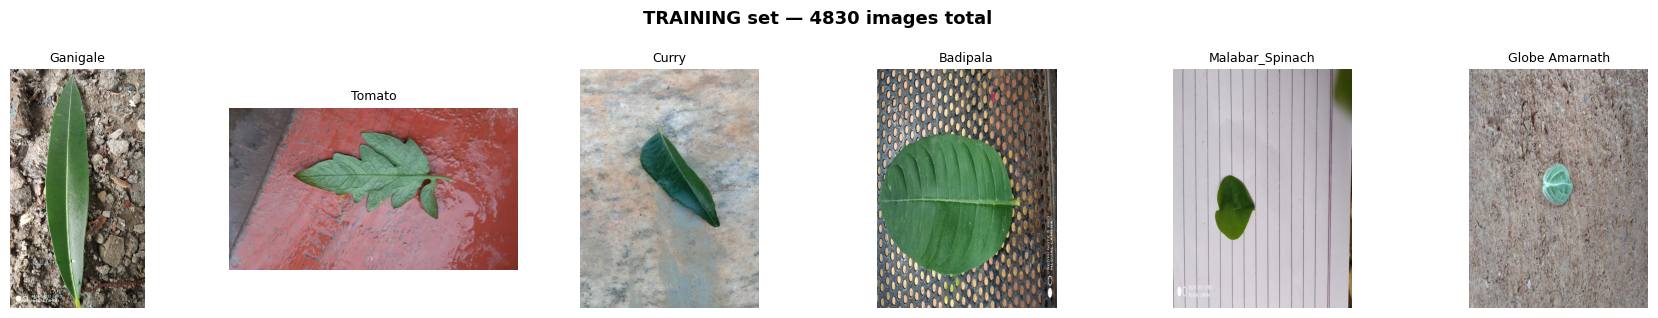

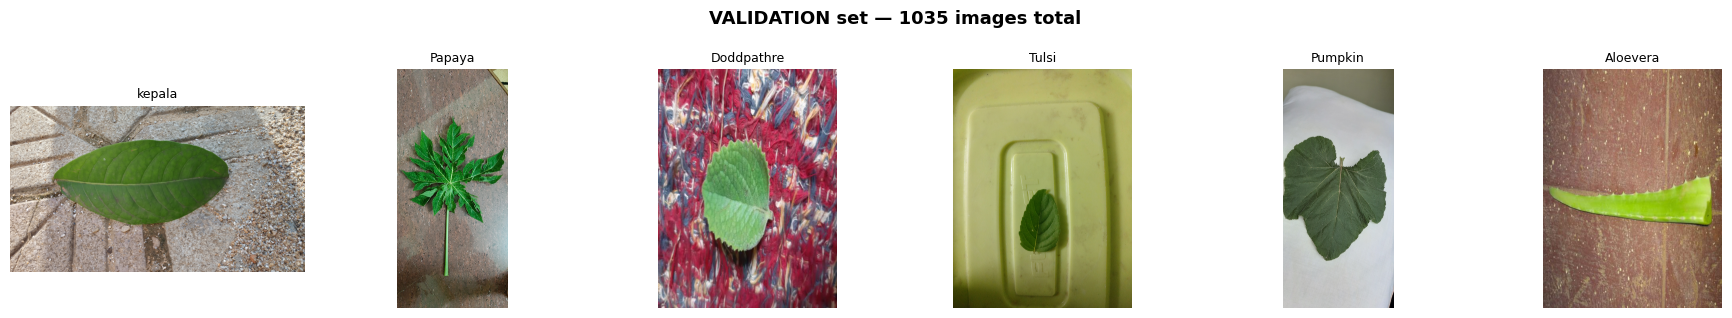

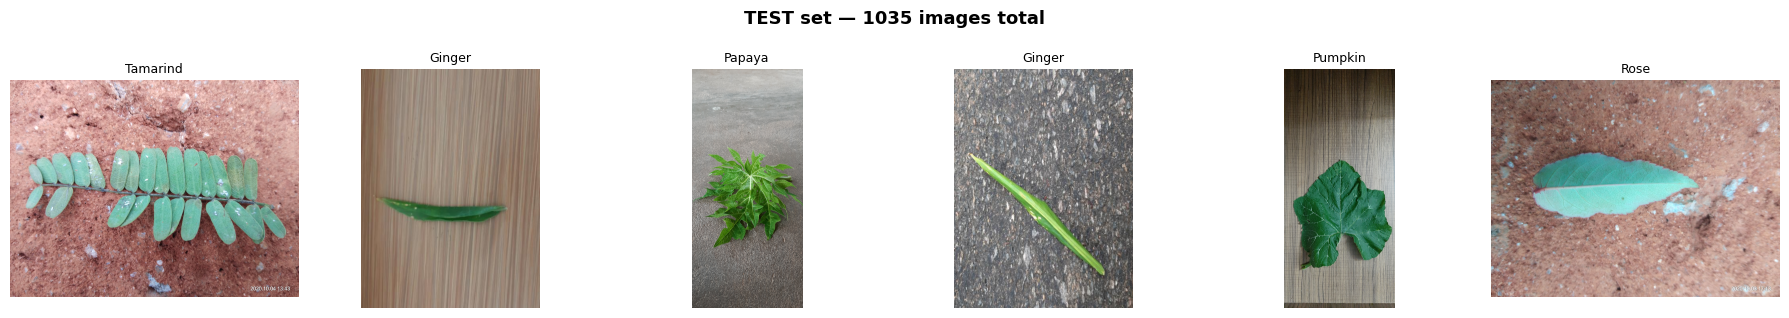

In [26]:
# ============================================================
# CELL 9 — VISUALIZE SAMPLE IMAGES FROM EACH SPLIT
# ============================================================
# Shows exactly which physical images fall into train/val/test, so it's
# visually obvious the three sets are disjoint and each still spans multiple
# species — not just numbers in a table.

def show_split_samples(indices, split_name, n_samples=6):
    chosen = np.random.RandomState(RANDOM_STATE).choice(indices, size=min(n_samples, len(indices)), replace=False)
    fig, axes = plt.subplots(1, len(chosen), figsize=(3 * len(chosen), 3.2))
    if len(chosen) == 1:
        axes = [axes]
    for ax, idx in zip(axes, chosen):
        img = cv2.imread(image_paths[idx])
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        ax.imshow(img_rgb)
        ax.set_title(raw_labels[idx], fontsize=9)
        ax.axis("off")
    fig.suptitle(f"{split_name} set — {len(indices)} images total", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


show_split_samples(TRAIN_IDX, "TRAINING")
show_split_samples(VAL_IDX, "VALIDATION")
show_split_samples(TEST_IDX, "TEST")


In [27]:
# ============================================================
# CELL 10 —  SCALED FEATURES (scalers fit on TRAIN ONLY)
# ============================================================

FINAL_FEATURE_GROUPS = ["shape", "color", "texture", "vein"]  

final_scalers = {}
scaled_groups_final = {}
for name in FINAL_FEATURE_GROUPS:
    arr, cols = feature_groups_raw[name]
    scaler = StandardScaler()
    scaler.fit(arr[TRAIN_IDX])          # fit on TRAIN rows only
    final_scalers[name] = scaler
    scaled_groups_final[name] = scaler.transform(arr)  # transform is applied to ALL rows

print("Re-fit scalers on TRAIN_IDX only, for groups:", FINAL_FEATURE_GROUPS)


def build_feature_matrix(indices):
    """Concatenates the fixed feature-group order for the given row indices."""
    return np.hstack([scaled_groups_final[g][indices] for g in FINAL_FEATURE_GROUPS])




Re-fit scalers on TRAIN_IDX only, for groups: ['shape', 'color', 'texture', 'vein']


In [28]:
X_train = build_feature_matrix(TRAIN_IDX)
X_val = build_feature_matrix(VAL_IDX)
X_test = build_feature_matrix(TEST_IDX)
print(f"Feature matrix shapes -> train: {X_train.shape}, val: {X_val.shape}, test: {X_test.shape}")

Feature matrix shapes -> train: (4830, 117), val: (1035, 117), test: (1035, 117)


In [29]:
# ============================================================
# CELL 11 — DEFINE CLASSIFIERS
# ============================================================

def build_classifiers():
    """A fresh set of un-fitted classifier instances."""
    return {
        "Random Forest": RandomForestClassifier(
            n_estimators=200,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),

        "LightGBM": LGBMClassifier(
            n_estimators=400,
            learning_rate=0.05,
            num_leaves=15,
            min_child_samples=5,
            random_state=RANDOM_STATE,
            verbosity=-1,
            n_jobs=-1
        ),

        "SVM": SVC(
            kernel="rbf",
            C=10,
            gamma="scale",
            random_state=RANDOM_STATE
        ),

        "Naive Bayes": GaussianNB(),

        "KNN": KNeighborsClassifier(
            n_neighbors=5,
            n_jobs=-1
        ),
    }

In [30]:
# ============================================================
# CELL 12 — TRAIN EVERY FEATURE-GROUP COMBINATION x EVERY CLASSIFIER
# ============================================================

group_names = ["shape", "color", "texture", "vein"]

results = []
predictions_store = {}

combo_counter = 0

total_combos = sum(
    1 for r in range(1, len(group_names) + 1)
    for _ in itertools.combinations(group_names, r)
)

num_classifiers = len(build_classifiers())

print(
    f"Total feature-group combinations to test: {total_combos} "
    f"(x{num_classifiers} classifiers = "
    f"{total_combos * num_classifiers} runs)"
)


for r in range(1, len(group_names) + 1):

    for combo in itertools.combinations(group_names, r):

        combo_counter += 1
        combo_str = "+".join(combo)

        # Build features using ONLY the selected feature groups.
        X_train_combo = np.hstack([
            scaled_groups_final[g][TRAIN_IDX]
            for g in combo
        ])

        X_val_combo = np.hstack([
            scaled_groups_final[g][VAL_IDX]
            for g in combo
        ])

        print(
            f"\n[{combo_counter}/{total_combos}] "
            f"Feature combo: {combo_str}  "
            f"(dim={X_train_combo.shape[1]})"
        )

        classifiers = build_classifiers()

        for model_name, model in classifiers.items():

            start = time.time()

            # Train only on TRAIN
            model.fit(X_train_combo, y_tr)

            # Evaluate only on VALIDATION
            y_pred = model.predict(X_val_combo)

            elapsed = time.time() - start

            acc = accuracy_score(y_va, y_pred)

            prec = precision_score(
                y_va,
                y_pred,
                average="macro",
                zero_division=0
            )

            rec = recall_score(
                y_va,
                y_pred,
                average="macro",
                zero_division=0
            )

            f1 = f1_score(
                y_va,
                y_pred,
                average="macro",
                zero_division=0
            )

            print(
                f"    {model_name:15s} | "
                f"Acc: {acc:.4f} | "
                f"Prec(macro): {prec:.4f} | "
                f"Rec(macro): {rec:.4f} | "
                f"F1(macro): {f1:.4f} | "
                f"{elapsed:.1f}s"
            )

            results.append({
                "combo": combo_str,
                "n_groups": r,
                "n_features": X_train_combo.shape[1],
                "classifier": model_name,
                "accuracy": acc,
                "precision_macro": prec,
                "recall_macro": rec,
                "f1_macro": f1,
                "train_time_sec": elapsed
            })

            predictions_store[
                (combo_str, model_name)
            ] = y_pred


results_df = pd.DataFrame(results)

# Rank by validation macro-F1
leaderboard = (
    results_df
    .sort_values("f1_macro", ascending=False)
    .reset_index(drop=True)
)

results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "all_combo_validation_results.csv"
    ),
    index=False
)

print(
    f"\nAll runs complete. Full validation results saved -> "
    f"{OUTPUT_DIR}/all_combo_validation_results.csv"
)

print("\n" + "=" * 90)
print("VALIDATION LEADERBOARD — ALL FEATURE COMBINATIONS")
print("=" * 90)

print(
    leaderboard.head(15)[
        [
            "combo",
            "classifier",
            "accuracy",
            "precision_macro",
            "recall_macro",
            "f1_macro"
        ]
    ].to_string(index=False)
)

best_row = leaderboard.iloc[0]

best_combo = best_row["combo"]
best_classifier = best_row["classifier"]

print(
    f"\nBest validation result: "
    f"{best_combo} + {best_classifier}  "
    f"(Acc={best_row['accuracy']:.4f}, "
    f"F1={best_row['f1_macro']:.4f})"
)

Total feature-group combinations to test: 15 (x5 classifiers = 75 runs)

[1/15] Feature combo: shape  (dim=14)
    Random Forest   | Acc: 0.4222 | Prec(macro): 0.4254 | Rec(macro): 0.4214 | F1(macro): 0.4118 | 3.2s
    LightGBM        | Acc: 0.3990 | Prec(macro): 0.4204 | Rec(macro): 0.4027 | F1(macro): 0.3996 | 22.3s
    SVM             | Acc: 0.3382 | Prec(macro): 0.3087 | Rec(macro): 0.3335 | F1(macro): 0.3105 | 2.0s
    Naive Bayes     | Acc: 0.1816 | Prec(macro): 0.1501 | Rec(macro): 0.2131 | F1(macro): 0.1485 | 0.0s
    KNN             | Acc: 0.2589 | Prec(macro): 0.2477 | Rec(macro): 0.2686 | F1(macro): 0.2458 | 0.0s

[2/15] Feature combo: color  (dim=57)
    Random Forest   | Acc: 0.5333 | Prec(macro): 0.5716 | Rec(macro): 0.5324 | F1(macro): 0.5323 | 5.6s
    LightGBM        | Acc: 0.4870 | Prec(macro): 0.5018 | Rec(macro): 0.4739 | F1(macro): 0.4699 | 46.1s
    SVM             | Acc: 0.4367 | Prec(macro): 0.4634 | Rec(macro): 0.4429 | F1(macro): 0.4414 | 4.0s
    Naive Bayes 

In [31]:
# ============================================================
# CELL 13 — FINAL LEADERBOARD & BEST FEATURE COMBINATION
# ============================================================
# Rank primarily by F1 (macro) since it balances precision and recall across
# all classes, rather than accuracy alone which can hide poor performance
# on smaller/harder classes.

leaderboard = results_df.sort_values(
    "f1_macro",
    ascending=False
).reset_index(drop=True)

print("=" * 90)
print("TOP 15 (feature combination x classifier) BY MACRO F1-SCORE")
print("=" * 90)

print(
    leaderboard.head(15)[
        [
            "combo",
            "classifier",
            "accuracy",
            "precision_macro",
            "recall_macro",
            "f1_macro",
            "n_features"
        ]
    ].to_string(index=False)
)


# Best classifier PER combo-size, so you can see whether adding more feature
# groups actually helps or just adds noise/overfitting risk.
print("\n" + "=" * 90)
print("BEST RESULT AT EACH COMBINATION SIZE (1 to 4 feature groups)")
print("=" * 90)

best_per_size = leaderboard.loc[
    leaderboard.groupby("n_groups")["f1_macro"].idxmax()
]

print(
    best_per_size[
        [
            "n_groups",
            "combo",
            "classifier",
            "accuracy",
            "f1_macro"
        ]
    ].to_string(index=False)
)


# The single best (combo, classifier) pair overall
best_row = leaderboard.iloc[0]

best_combo = best_row["combo"]
best_model = best_row["classifier"]

print("\n" + "=" * 90)
print(f"OVERALL BEST: {best_combo}  +  {best_model}")

print(
    f"Accuracy={best_row['accuracy']:.4f}  "
    f"Precision(macro)={best_row['precision_macro']:.4f}  "
    f"Recall(macro)={best_row['recall_macro']:.4f}  "
    f"F1(macro)={best_row['f1_macro']:.4f}"
)

print("=" * 90)


# Full, detailed per-class report — generated ONLY for the winning
# combination, using the validation predictions already stored.
best_preds = predictions_store[(best_combo, best_model)]

print("\nDetailed classification report for the best combination:\n")

print(
    classification_report(
        y_va,
        best_preds,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


# Save the complete validation leaderboard
leaderboard.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "leaderboard_sorted.csv"
    ),
    index=False
)

print(
    f"\nSorted leaderboard saved -> "
    f"{OUTPUT_DIR}/leaderboard_sorted.csv"
)

TOP 15 (feature combination x classifier) BY MACRO F1-SCORE
                   combo    classifier  accuracy  precision_macro  recall_macro  f1_macro  n_features
shape+color+texture+vein           SVM  0.729469         0.762807      0.731362  0.737981         117
     shape+color+texture           SVM  0.726570         0.757992      0.727604  0.734052         103
shape+color+texture+vein Random Forest  0.708213         0.769128      0.707885  0.716693         117
     shape+color+texture Random Forest  0.709179         0.746423      0.710239  0.714696         103
shape+color+texture+vein      LightGBM  0.700483         0.723101      0.685765  0.688185         117
      color+texture+vein           SVM  0.679227         0.711991      0.679764  0.685618         103
     shape+color+texture      LightGBM  0.683092         0.705155      0.674495  0.673257         103
           color+texture           SVM  0.655072         0.687176      0.657338  0.663656          89
           color+textu

In [32]:
# ============================================================
# CELL 14 — VALIDATION-BASED SVM HYPERPARAMETER TUNING (BEST MODEL)
# ============================================================

from sklearn.model_selection import ParameterGrid

best_combo_groups = best_combo.split("+")

X_train_best = np.hstack([
    scaled_groups_final[g][TRAIN_IDX]
    for g in best_combo_groups
])

X_val_best = np.hstack([
    scaled_groups_final[g][VAL_IDX]
    for g in best_combo_groups
])

param_grid = {
    "C": [1, 5, 10, 20, 50],
    "gamma": ["scale", 0.01, 0.1]
}

print(
    f"Tuning SVM using TRAIN -> fit, VALIDATION -> score "
    f"(test set untouched):\n"
)

val_tuning_results = []

for params in ParameterGrid(param_grid):

    model = SVC(
        kernel="rbf",
        random_state=RANDOM_STATE,
        **params
    )

    start = time.time()

    model.fit(X_train_best, y_tr)

    val_pred = model.predict(X_val_best)

    elapsed = time.time() - start

    val_acc = accuracy_score(y_va, val_pred)

    val_f1 = f1_score(
        y_va,
        val_pred,
        average="macro",
        zero_division=0
    )

    print(
        f"  C={params['C']:>4} "
        f"gamma={str(params['gamma']):>6} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val F1(macro): {val_f1:.4f}"
    )

    val_tuning_results.append({
        **params,
        "val_accuracy": val_acc,
        "val_f1_macro": val_f1,
        "train_time_sec": elapsed
    })


val_tuning_df = (
    pd.DataFrame(val_tuning_results)
    .sort_values("val_f1_macro", ascending=False)
    .reset_index(drop=True)
)

best_params = val_tuning_df.iloc[0][["C", "gamma"]].to_dict()

print(
    f"\nBest hyperparameters "
    f"(chosen on VALIDATION set): {best_params}"
)

print(
    f"Best validation F1(macro): "
    f"{val_tuning_df.iloc[0]['val_f1_macro']:.4f}"
)

Tuning SVM using TRAIN -> fit, VALIDATION -> score (test set untouched):

  C=   1 gamma= scale | Val Acc: 0.6222 | Val F1(macro): 0.6171
  C=   1 gamma=  0.01 | Val Acc: 0.6406 | Val F1(macro): 0.6406
  C=   1 gamma=   0.1 | Val Acc: 0.2242 | Val F1(macro): 0.2611
  C=   5 gamma= scale | Val Acc: 0.7304 | Val F1(macro): 0.7381
  C=   5 gamma=  0.01 | Val Acc: 0.7266 | Val F1(macro): 0.7355
  C=   5 gamma=   0.1 | Val Acc: 0.2647 | Val F1(macro): 0.3204
  C=  10 gamma= scale | Val Acc: 0.7295 | Val F1(macro): 0.7380
  C=  10 gamma=  0.01 | Val Acc: 0.7246 | Val F1(macro): 0.7326
  C=  10 gamma=   0.1 | Val Acc: 0.2647 | Val F1(macro): 0.3204
  C=  20 gamma= scale | Val Acc: 0.7285 | Val F1(macro): 0.7367
  C=  20 gamma=  0.01 | Val Acc: 0.7246 | Val F1(macro): 0.7326
  C=  20 gamma=   0.1 | Val Acc: 0.2647 | Val F1(macro): 0.3204
  C=  50 gamma= scale | Val Acc: 0.7285 | Val F1(macro): 0.7367
  C=  50 gamma=  0.01 | Val Acc: 0.7246 | Val F1(macro): 0.7326
  C=  50 gamma=   0.1 | Val Ac

In [33]:
# ============================================================
# CELL 15 — FINALIZE SCALERS + FINAL MODEL
# ============================================================

TRAINVAL_IDX = np.concatenate([
    TRAIN_IDX,
    VAL_IDX
])

print(
    f"Refitting final preprocessing and model on "
    f"TRAIN+VALIDATION ({len(TRAINVAL_IDX)} images)..."
)

# ------------------------------------------------------------
# Refit scalers using TRAIN + VALIDATION
# ------------------------------------------------------------

final_scalers = {}
scaled_groups_final_model = {}

for name in best_combo_groups:

    arr, cols = feature_groups_raw[name]

    scaler = StandardScaler()

    # Fit only on data available before the final test evaluation
    scaler.fit(arr[TRAINVAL_IDX])

    final_scalers[name] = scaler

    scaled_groups_final_model[name] = scaler.transform(arr)


# ------------------------------------------------------------
# Build final feature matrices
# ------------------------------------------------------------

X_trainval = np.hstack([
    scaled_groups_final_model[g][TRAINVAL_IDX]
    for g in best_combo_groups
])

X_test_final = np.hstack([
    scaled_groups_final_model[g][TEST_IDX]
    for g in best_combo_groups
])

y_trainval = y_all[TRAINVAL_IDX]


# ------------------------------------------------------------
# Train final SVM
# ------------------------------------------------------------

final_model = SVC(
    kernel="rbf",
    probability=True,
    random_state=RANDOM_STATE,
    **best_params
)

start = time.time()

final_model.fit(
    X_trainval,
    y_trainval
)

elapsed = time.time() - start

print(
    f"Final model trained in {elapsed:.1f}s"
)

print(
    f"Final feature combination: {best_combo}"
)

print(
    f"Final SVM parameters: {best_params}"
)

print(
    f"Training samples used: {len(TRAINVAL_IDX)}"
)

Refitting final preprocessing and model on TRAIN+VALIDATION (5865 images)...
Final model trained in 20.1s
Final feature combination: shape+color+texture+vein
Final SVM parameters: {'C': 5, 'gamma': 'scale'}
Training samples used: 5865


TRAIN + VALIDATION CONFUSION MATRIX
Training/Validation Accuracy: 0.9918


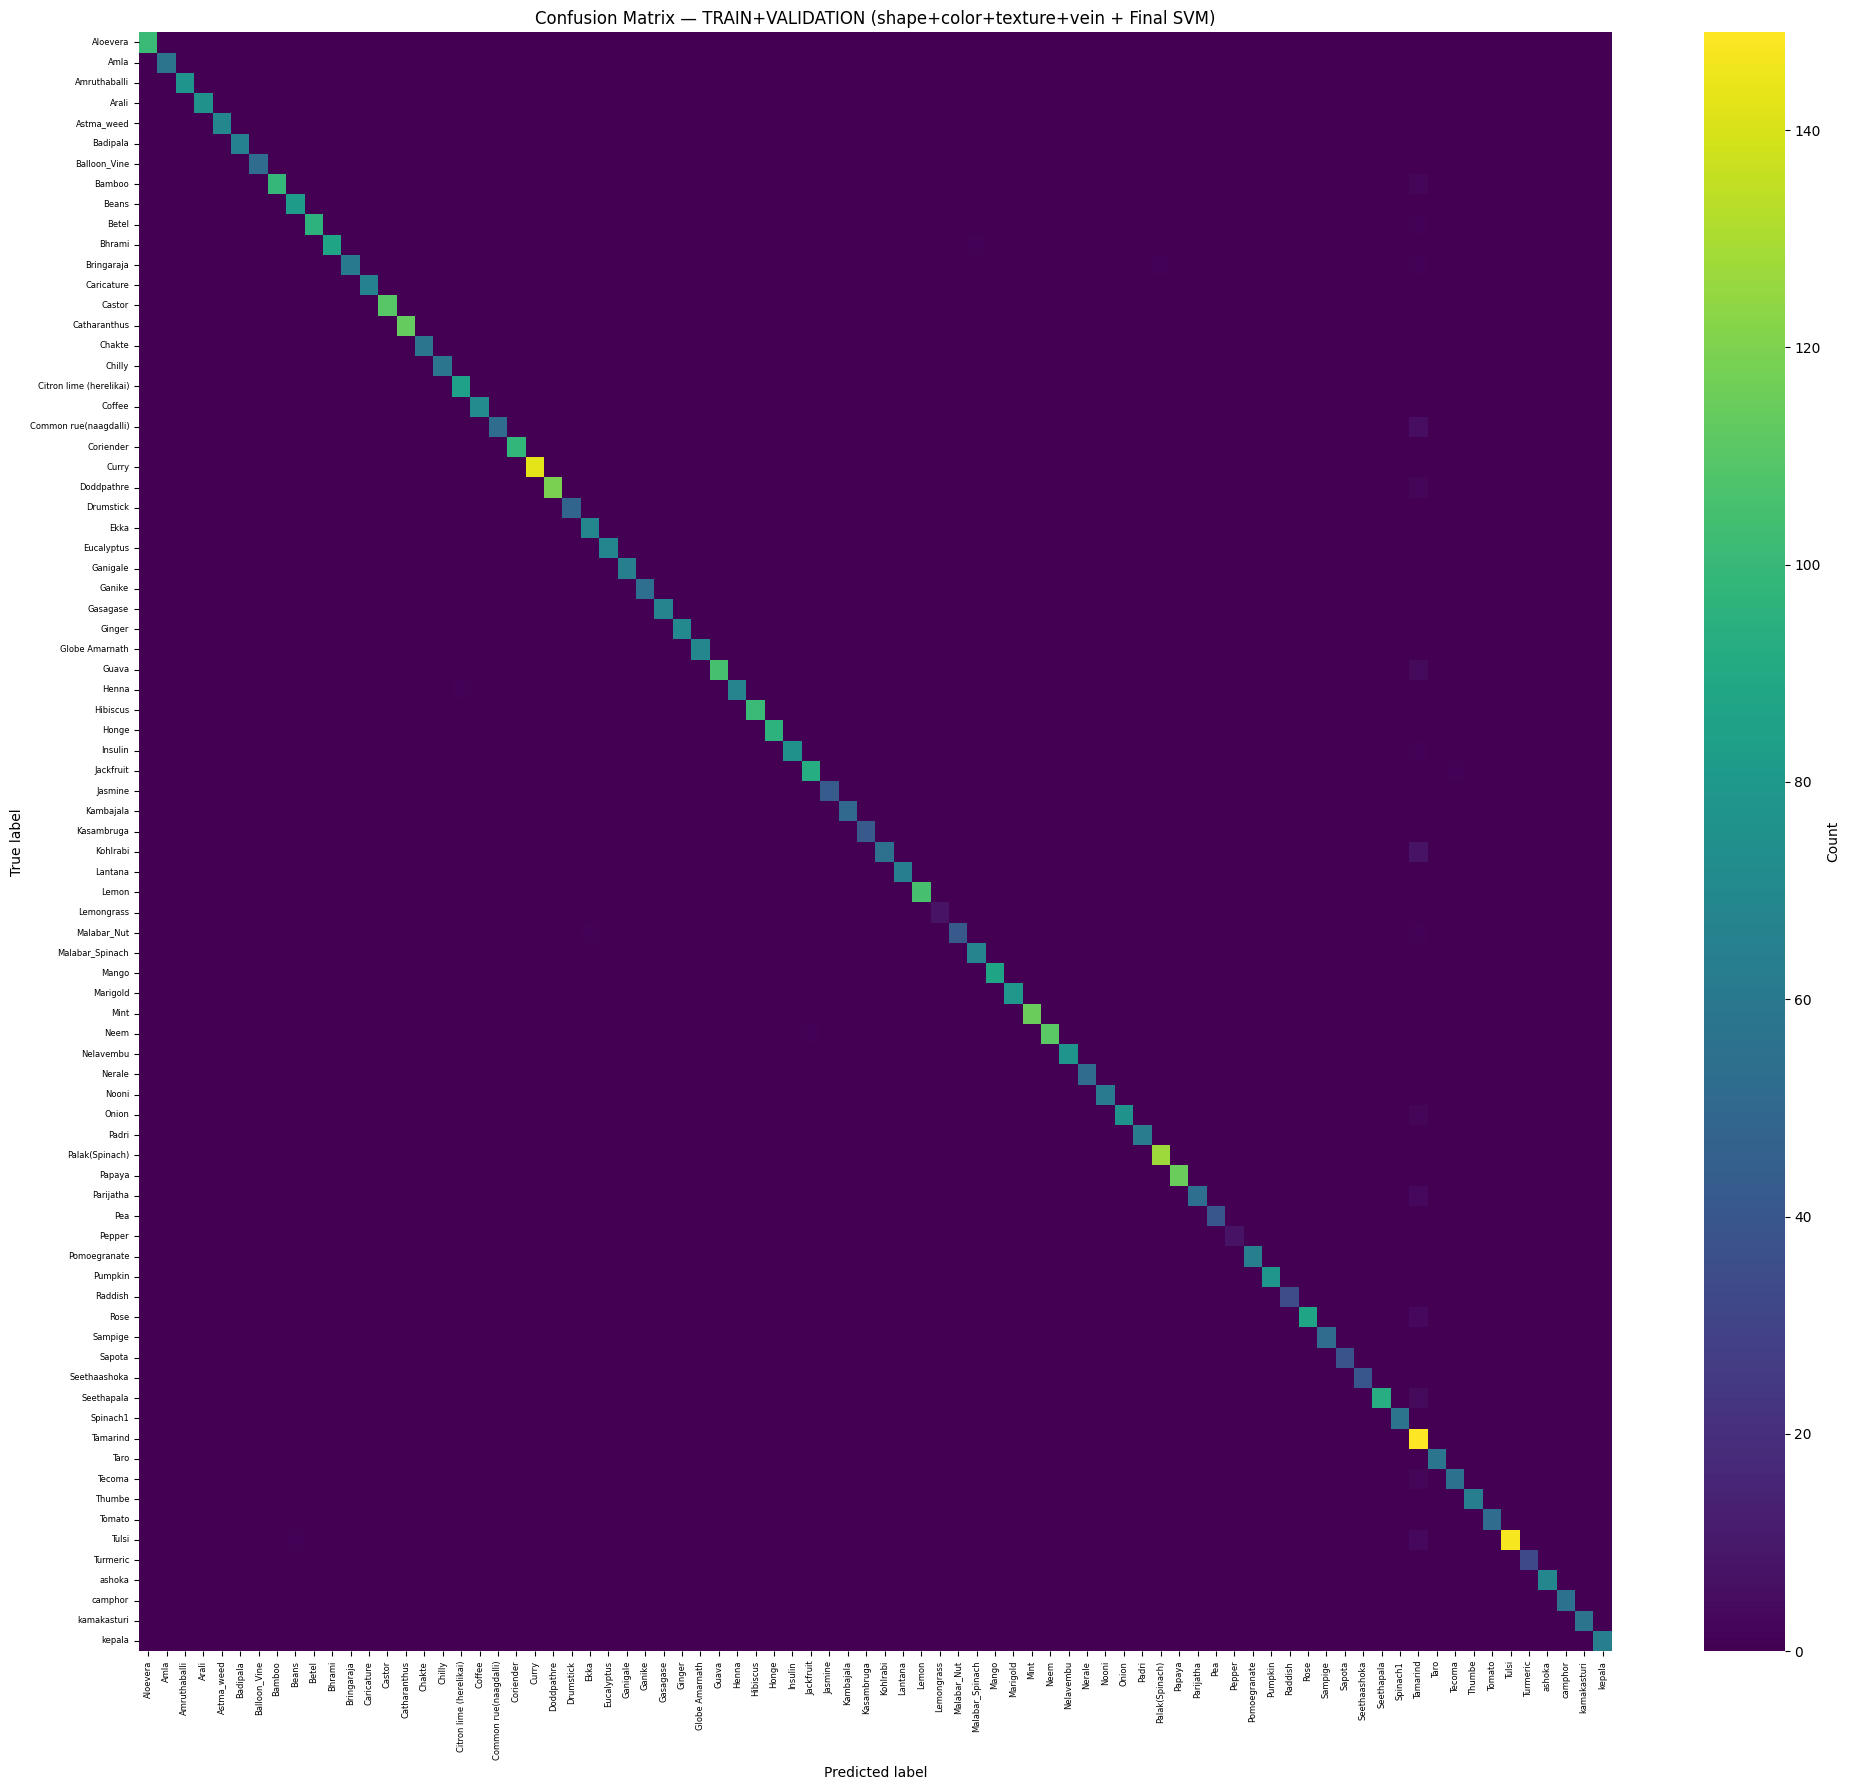

In [40]:
# ============================================================
# CELL 16 — TRAINING CONFUSION MATRIX
# ============================================================
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns
y_trainval_pred = final_model.predict(X_trainval)

trainval_acc = accuracy_score(
    y_trainval,
    y_trainval_pred
)

print("=" * 60)
print("TRAIN + VALIDATION CONFUSION MATRIX")
print("=" * 60)
print(f"Training/Validation Accuracy: {trainval_acc:.4f}")

cm_trainval = confusion_matrix(
    y_trainval,
    y_trainval_pred
)

plt.figure(figsize=(20, 18))

sns.heatmap(
    cm_trainval,
    cmap="viridis",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    cbar_kws={"label": "Count"}
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title(
    f"Confusion Matrix — TRAIN+VALIDATION "
    f"({best_combo} + Final SVM)"
)

plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "trainval_confusion_matrix.png"
    ),
    dpi=150
)

plt.show()

In [42]:
# ============================================================
# CELL 17 — FINAL TEST EVALUATION
# ============================================================

y_test_pred = final_model.predict(X_test_final)

test_acc = accuracy_score(
    y_te,
    y_test_pred
)

test_prec = precision_score(
    y_te,
    y_test_pred,
    average="macro",
    zero_division=0
)

test_rec = recall_score(
    y_te,
    y_test_pred,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    y_te,
    y_test_pred,
    average="macro",
    zero_division=0
)

print("=" * 60)
print("FINAL TEST SET RESULTS (UNSEEN DATA)")
print("=" * 60)

print(f"Accuracy:         {test_acc:.4f}")
print(f"Precision(macro): {test_prec:.4f}")
print(f"Recall(macro):    {test_rec:.4f}")
print(f"F1(macro):        {test_f1:.4f}")

print()

print(
    classification_report(
        y_te,
        y_test_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

FINAL TEST SET RESULTS (UNSEEN DATA)
Accuracy:         0.7585
Precision(macro): 0.7707
Recall(macro):    0.7509
F1(macro):        0.7537

                         precision    recall  f1-score   support

               Aloevera       0.94      0.94      0.94        17
                   Amla       0.62      0.50      0.56        10
           Amruthaballi       0.71      0.71      0.71        14
                  Arali       0.92      0.86      0.89        14
             Astma_weed       0.69      0.85      0.76        13
               Badipala       0.82      0.82      0.82        11
           Balloon_Vine       0.88      0.78      0.82         9
                 Bamboo       0.76      0.76      0.76        17
                  Beans       0.74      0.93      0.82        15
                  Betel       0.87      0.76      0.81        17
                 Bhrami       0.67      0.62      0.65        16
             Bringaraja       0.78      0.64      0.70        11
             Car

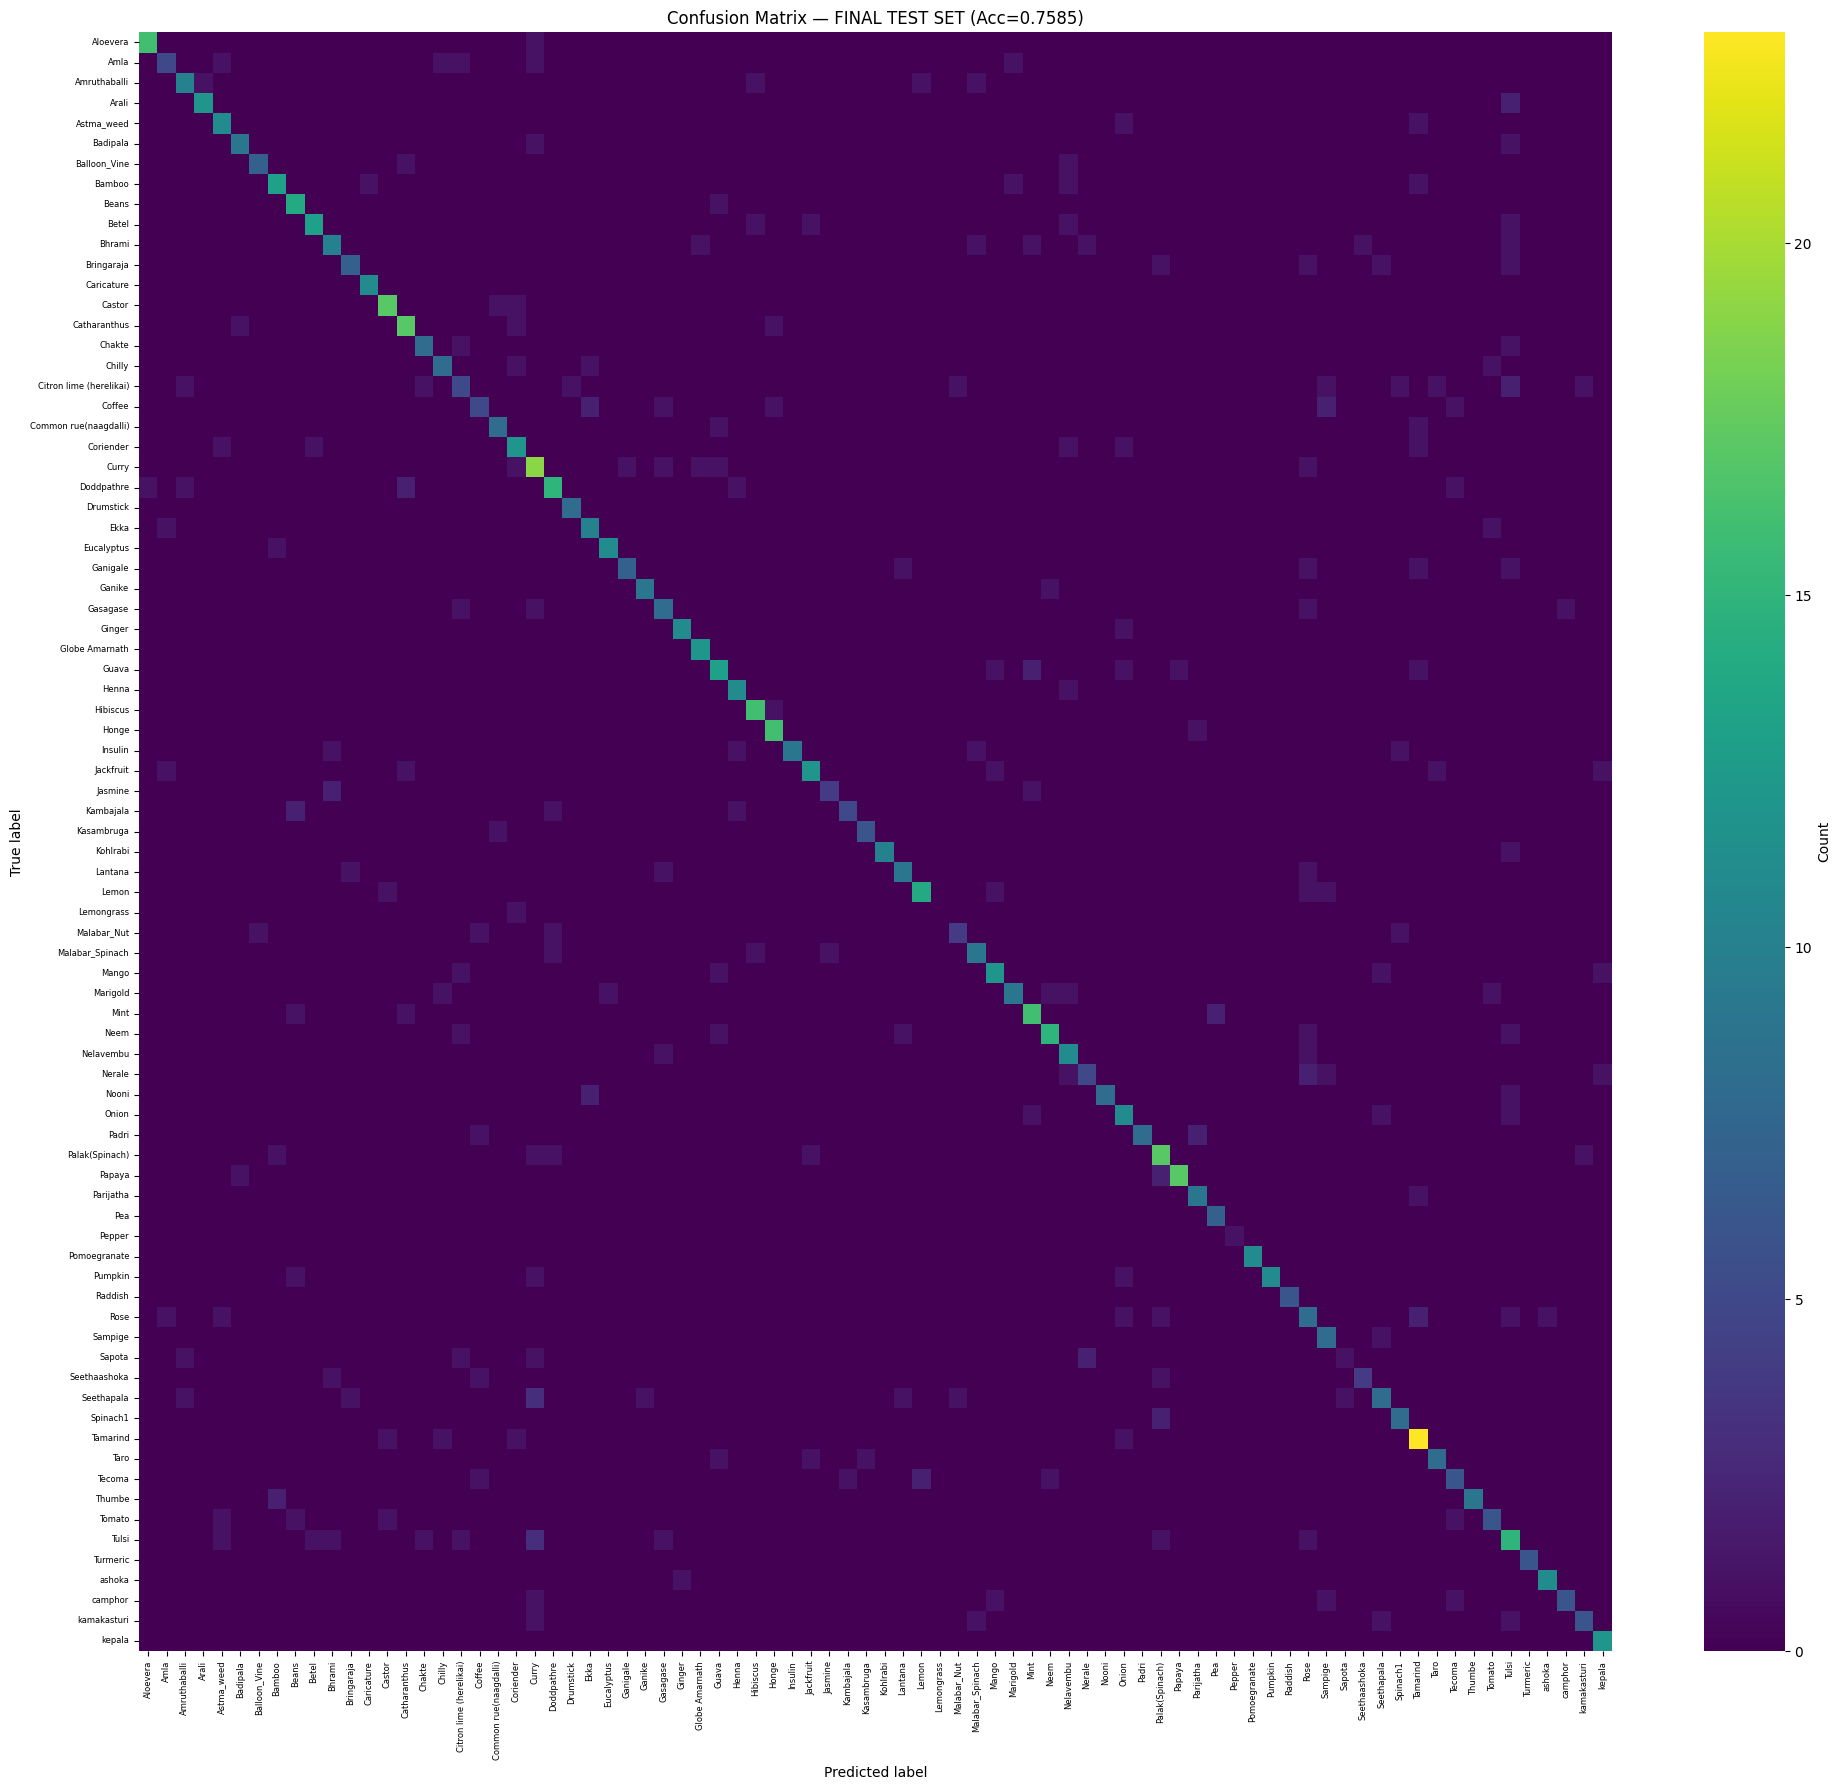

In [43]:
# ============================================================
# CELL 18 — FINAL TEST CONFUSION MATRIX
# ============================================================

cm_final = confusion_matrix(
    y_te,
    y_test_pred
)

plt.figure(figsize=(20, 18))

sns.heatmap(
    cm_final,
    cmap="viridis",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    cbar_kws={"label": "Count"}
)

plt.xlabel("Predicted label")
plt.ylabel("True label")

plt.title(
    f"Confusion Matrix — FINAL TEST SET "
    f"(Acc={test_acc:.4f})"
)

plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "final_test_confusion_matrix.png"
    ),
    dpi=150
)

plt.show()

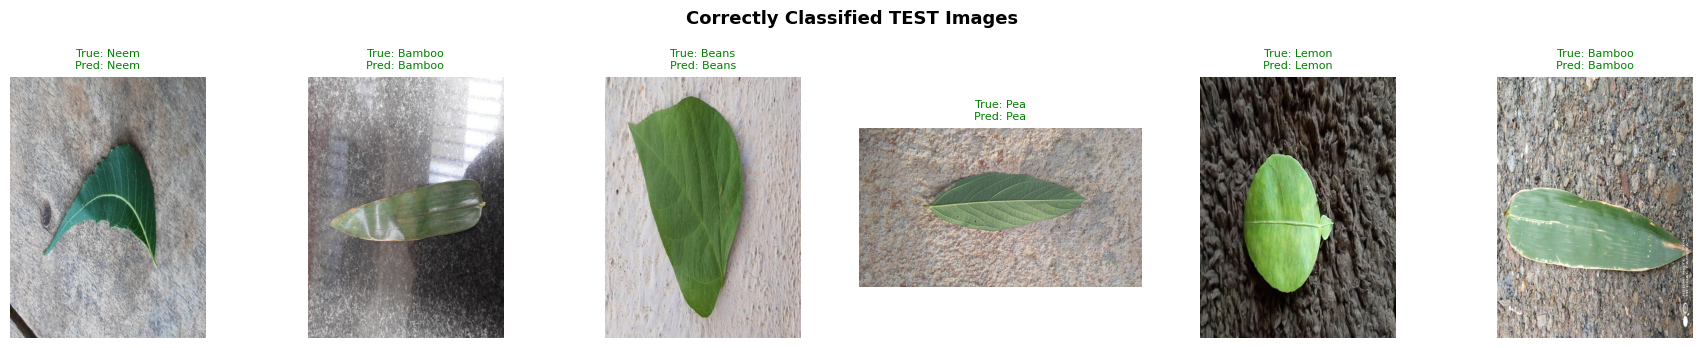

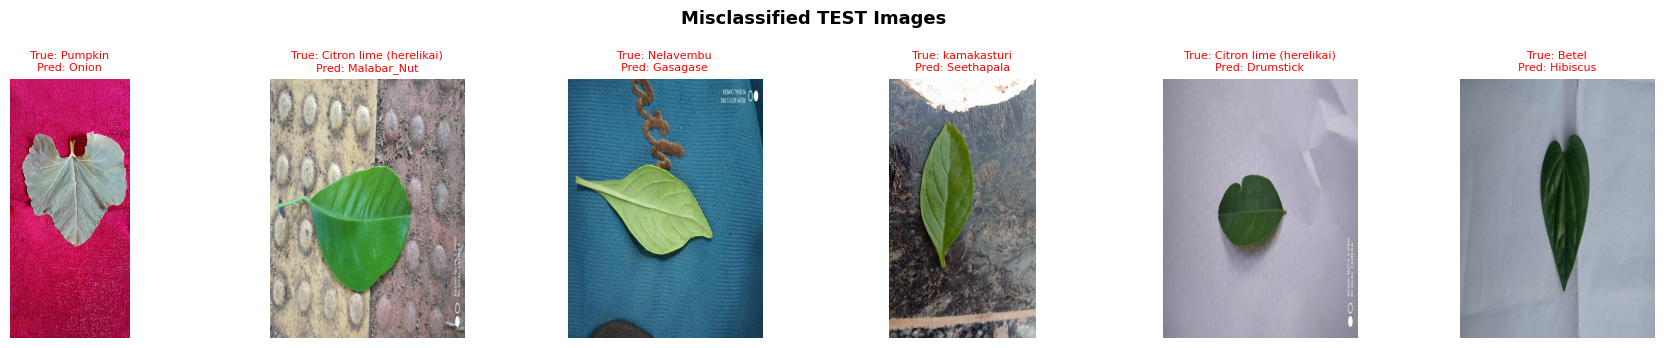

In [45]:
# ============================================================
# CELL 19 — Correct / Misclassified Images
# ============================================================
# --- Sample predictions with images: correct vs. incorrect, on TEST set ---

def show_prediction_samples(indices_subset, preds_subset, n_samples=6, title=""):

    n_samples = min(n_samples, len(indices_subset))

    if n_samples == 0:
        print(f"(no samples for: {title})")
        return

    chosen = np.random.RandomState(RANDOM_STATE).choice(
        len(indices_subset),
        size=n_samples,
        replace=False
    )

    fig, axes = plt.subplots(
        1,
        n_samples,
        figsize=(3 * n_samples, 3.5)
    )

    if n_samples == 1:
        axes = [axes]

    for ax, i in zip(axes, chosen):

        # Original dataset index
        global_idx = indices_subset[i]

        img = cv2.cvtColor(
            cv2.imread(image_paths[global_idx]),
            cv2.COLOR_BGR2RGB
        )

        # Get TRUE label using the original dataset index
        true_label = label_encoder.classes_[y_all[global_idx]]

        # Prediction is aligned with indices_subset
        pred_label = label_encoder.classes_[preds_subset[i]]

        color = "green" if true_label == pred_label else "red"

        ax.imshow(img)
        ax.set_title(
            f"True: {true_label}\nPred: {pred_label}",
            fontsize=8,
            color=color
        )
        ax.axis("off")

    fig.suptitle(
        title,
        fontsize=13,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# CORRECTLY CLASSIFIED TEST IMAGES
# ------------------------------------------------------------

correct_mask = (y_te == y_test_pred)

show_prediction_samples(
    TEST_IDX[correct_mask],
    y_test_pred[correct_mask],
    title="Correctly Classified TEST Images"
)


# ------------------------------------------------------------
# MISCLASSIFIED TEST IMAGES
# ------------------------------------------------------------

show_prediction_samples(
    TEST_IDX[~correct_mask],
    y_test_pred[~correct_mask],
    title="Misclassified TEST Images"
)

In [46]:
# ============================================================
# CELL 20 — PREDICT A NEW LEAF IMAGE (e.g. downloaded from Google Images)
# ============================================================
# HOW TO GET AN IMAGE IN:
#   Option A (easiest on Kaggle): drag-and-drop the image file into the
#   Kaggle notebook's file browser under /kaggle/working/, then set
#   NEW_IMAGE_PATH to that file's path.
#   Option B: if you have a direct image URL (right-click an image on
#   Google Images -> "Copy image address"), use the download helper below.

import urllib.request


def download_image_from_url(url, save_path="/kaggle/working/new_leaf.jpg"):
    """Downloads an image from a direct URL to disk and returns the local path."""
    urllib.request.urlretrieve(url, save_path)
    print(f"Downloaded -> {save_path}")
    return save_path


def predict_leaf_image(img_path, model=final_model, top_k=3):
    """
    Runs a brand-new leaf image through the EXACT same preprocessing and
    feature-extraction pipeline used for training, using the best feature
    combination selected on the validation set and the SAME fitted scalers.
    """

    bgr, gray_eq, mask = load_and_segment(img_path)

    if bgr is None or mask is None or mask.sum() == 0:
        print("Could not read the image or find a leaf in it — try a clearer photo "
              "with a plain background.")
        return

    # Extract the same feature groups used during training.
    shape_f = extract_shape_features(mask)
    color_f = extract_color_features(bgr, mask)
    texture_f = extract_texture_features(gray_eq, mask)
    vein_f = extract_vein_edge_features(gray_eq, mask)

    raw_feats = {
        "shape": shape_f,
        "color": color_f,
        "texture": texture_f,
        "vein": vein_f
    }

    # Use ONLY the feature groups selected as the best combination.
    scaled_feats = [
        final_scalers[g].transform(
            raw_feats[g].reshape(1, -1)
        )
        for g in best_combo_groups
    ]

    X_new = np.hstack(scaled_feats)

    # Predict the species.
    pred_class_idx = model.predict(X_new)[0]
    pred_label = label_encoder.classes_[pred_class_idx]

    # Show top-k predictions with confidence, if supported.
    top_k_text = ""

    if hasattr(model, "predict_proba"):
        probs = model.predict_proba(X_new)[0]

        top_indices = np.argsort(probs)[::-1][:top_k]

        top_k_text = "\n".join(
            f"{i+1}. {label_encoder.classes_[idx]}  "
            f"({probs[idx] * 100:.1f}%)"
            for i, idx in enumerate(top_indices)
        )

    img_rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(5, 5))
    plt.imshow(img_rgb)
    plt.axis("off")
    plt.title(
        f"Predicted: {pred_label}",
        fontsize=13,
        fontweight="bold"
    )
    plt.show()

    print(f"Predicted species: {pred_label}")

    if top_k_text:
        print(f"\nTop {top_k} predictions:\n{top_k_text}")

    return pred_label




Downloaded -> /kaggle/working/aloe_vera_test.jpg


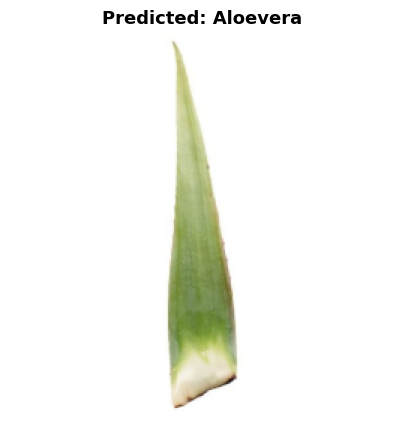

Predicted species: Aloevera

Top 3 predictions:
1. Aloevera  (16.6%)
2. Tulsi  (8.3%)
3. Onion  (7.0%)


np.str_('Aloevera')

In [47]:
# ============================================================
# TEST — ALOE VERA IMAGE FROM URL
# ============================================================

ALOE_VERA_URL = (
    "https://www.melissas.com/cdn/shop/files/"
    "4-pounds-image-of-aloe-vera-leaves-other-35614866047020_600x600.jpg"
    "?v=1699375426"
)

NEW_IMAGE_PATH = download_image_from_url(
    ALOE_VERA_URL,
    "/kaggle/working/aloe_vera_test.jpg"
)

predict_leaf_image(NEW_IMAGE_PATH)

Downloaded -> /kaggle/working/tulsi_test.jpg


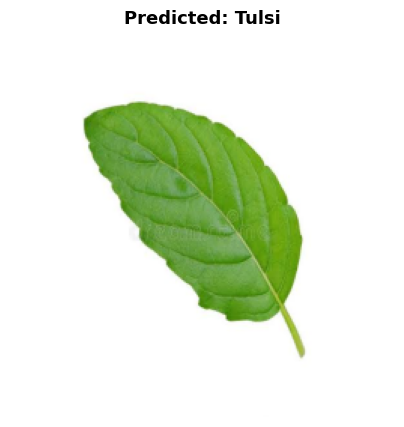

Predicted species: Tulsi

Top 3 predictions:
1. Tulsi  (12.5%)
2. Amruthaballi  (8.8%)
3. Aloevera  (5.9%)


np.str_('Tulsi')

In [61]:

# ============================================================
# TEST — TULSI LEAF IMAGE FROM URL
# ============================================================

TULSI_URL = (
    "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQe5TE_K6cQSP9MzqdLMi6u95L_ZLwOD99Ka8-hePR1Jw&s=10"
)

NEW_IMAGE_PATH = download_image_from_url(
    TULSI_URL,
    "/kaggle/working/tulsi_test.jpg"
)

predict_leaf_image(NEW_IMAGE_PATH)

Downloaded -> /kaggle/working/Kohlrabi_test.jpg


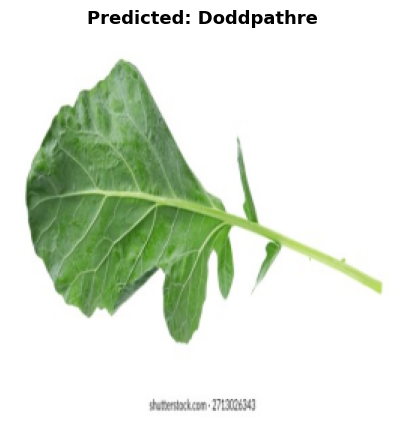

Predicted species: Doddpathre

Top 3 predictions:
1. Doddpathre  (12.7%)
2. Tulsi  (10.7%)
3. Onion  (9.9%)


np.str_('Doddpathre')

In [62]:

# ============================================================
# TEST — Kohlrabi  LEAF IMAGE FROM URL
# ============================================================

Kohlrabi_URL = (
    "https://www.shutterstock.com/image-photo/fresh-raw-kohlrabi-green-leaf-260nw-2713026343.jpg"
)

NEW_IMAGE_PATH = download_image_from_url(
    Kohlrabi_URL,
    "/kaggle/working/Kohlrabi_test.jpg"
)

predict_leaf_image(NEW_IMAGE_PATH)